# Group 2 — NLP take-home assignment (fall 2026)

| Name | Contribution |
|---|---|
| Selim Can Mutlu | Fine-tuning pipeline (Task 1) |
| Le Phuong Thao Hoàng | *to be filled in* |
| Deren Serçe | DAT and CDAT evaluation (Tasks 2A–2B) |

**How the outputs in this notebook were produced.** All outputs come from one end-to-end execution of this notebook; the configuration cell prints the hardware it ran on. On a CUDA GPU (Google Colab) the 7B model is loaded in 4-bit (QLoRA); on Apple Silicon it runs in bf16 on the MPS backend. Long steps save their results to disk (`artifacts/` for the adapter and checkpoints; `stimuli&outputs/raw_generations/` for every raw model output), so the notebook can be re-run, or resumed after a disconnect, without retraining or re-sampling.

**Deliverables produced by this notebook:** `stimuli&outputs/group2_DAT_scores.tsv`, `stimuli&outputs/group2_CDAT_scores.tsv`, `stimuli&outputs/group2_novelWord_scoring.tsv` (outputs; rubric scores by the group), `stimuli&outputs/group2_novelWord_autochecks.tsv`, and the LoRA adapter in `artifacts/finetuned_adapter/`. The reproducibility log is `stimuli&outputs/group2_reproducibility_log.txt`.

# NLP Assignment: Reproducibility, Fine-Tuning, and Creativity Evaluation

In this assignment you will reconstruct an LLM fine-tuning pipeline from a written project report, evaluate the effects of fine-tuning and decoding choices on creativity-oriented tasks, and compare your reconstruction with the original implementation once it is released.

The assignment is not about obtaining the highest score. It is about understanding how implementation details and evaluation choices affect the conclusions we draw from an NLP experiment. All papers referenced in the assignment are provided on Canvas and should be consulted while completing the assignment.

You will work in three stages:

1. **Reconstruct the fine-tuning pipeline from the report (no access to the original code).**
2. **Evaluate the base and fine-tuned models using the Divergent Association Task (DAT), the Conditional DAT (see Nakajima et al 2026 for both DAT and CDAT), and a novel-word task (see Ciaccio et al, 2025). Make sure to read the assignment first and identify which details from the source papers you need to understand: not all theoretical and technical details from these sources are relevant for the assignment. The novel-word generation task is inspired by Ciaccio and colleagues and is not intended to reproduce their experiments.**

Keep all generated outputs, scores, scripts, logs, and written reflections. They are part of the submission.
Files available in this folder, including this notebook, are named as group2_filename.ext: before submitting, replace the XX with your group number (e.g., group 9 should submit the notebook as group9_nlp_assignment_fall2026.ipynb)

##### Important: we purposefully do not release any function to check that your implementation is correct. The more you progress in your career, the more you have to deal with the fact that any meaningful task you will work on will not have a known answer you can use as ground truth. You need to develop strategies to ensure that what you developed is sensible and that you can trust your results.


## Grading emphasis

You will be assessed on:

- completeness and clarity of the reconstructed pipeline, not output: pay attention to the report and the details it does provide (those should be reproduced as faithfully as possible in your pipeline);
- quality of the reproducibility log: when information from the report is missing or ambiguous, it's important you document the issue, make reasonable choices and justify them well in the log, not that you guess exactly what the authors of the source report did;
- correctness and organization of the evaluation outputs;
- quality of the comparison with the original implementation: you should inspect your choices in relation to the original ones and analyze them, not compare performance;
- depth of the discussion about evaluation and reproducibility.

A negative or null result is not a bad result. What matters is whether you can explain what happened and why.

For all stochastic processes, set the seed = 111.

## Submission structure

Submit a single compressed folder containing:

- your code as a Colab Notebook, with all generated outputs visible and answers to the open questions as text blocks, with clear references to which task is being addressed by which code block;
- installation instructions (can be part of the Colab Notebook);
- your reproducibility log as a .txt file, using the file template provided in the folder - justifications of your choices should be limited to 50 words each;
- DAT/CDAT scores, as separate .tsv files (see specific instructions in each task). The file should contain the following columns: model (base or fine-tuned), temperature (0.5, 1, 1.5), repetition_id (for DAT, an integer) / cue word (for CDAT, a string), valid words (strings), score (float);
- the novel word evaluation, using the file template provided in the folder - justifications of the evaluation should be limited to 50 words each.

Only for CDAT, include the columns: novelty (float), appropriateness (float), passed gate (yes or no).

Your notebook should be self contained, so any external repo or software you rely upon should be included in the preamble of the notebook as code one can run.

Unless otherwise specified, answer open questions with no more than 150 words.

## Preamble — installation instructions

**Google Colab (GPU runtime):** put the folder `NLP Take Home Assignment` in the root of Google Drive (`MyDrive/NLP Take Home Assignment/`). It must contain this notebook, `stimuli&outputs/` (with `sample_cdat.txt`), `erowid_experiences.zip` (the corpus's `Experiences/` folder, zipped) and `nltk_data.zip` (WordNet, word list and POS tagger: NLTK refuses to download through Colab's proxy). Open the notebook from Drive, choose *Runtime → Change runtime type → GPU*, and *Run all*. The next cell installs the dependencies (plus `bitsandbytes` for 4-bit loading) and mounts Drive. All outputs, checkpoints included, are written to the Drive folder: after a disconnect, *Run all* again and training resumes from the last checkpoint.

**Local machine:** `python -m venv .venv && .venv/bin/pip install -r requirements.txt`, then run the notebook from the assignment folder with that environment (`.venv/bin/jupyter nbconvert --to notebook --execute --inplace group2_nlp_assignment_fall2026.ipynb --ExecutePreprocessor.timeout=-1`).

Models are downloaded automatically from the Hugging Face Hub; no access token is needed. Mistral-7B needs about 15 GB of disk per checkpoint. The SBERT model `all-MiniLM-L6-v2` and the NLTK data (WordNet, word list, POS tagger) are also downloaded automatically.

In [2]:
# PREAMBLE — dependencies (pinned versions used for the reported run)
import sys, subprocess, importlib.metadata as md

REQUIREMENTS = ["transformers==5.18.0", "peft==0.21.1", "accelerate==1.15.0", "datasets==5.0.1",
                "sentence-transformers==6.1.0", "nltk==3.10.3", "rapidfuzz==3.14.6"]
if "google.colab" in sys.modules:
    # Colab already ships torch, numpy, pandas, scipy, statsmodels, matplotlib and seaborn; these are left untouched
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *REQUIREMENTS, "bitsandbytes"], check=True)
    # Colab ships torchao 0.10, which peft 0.21 rejects with an ImportError when adding LoRA layers; it is not used here
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=False)
    from google.colab import drive
    drive.mount("/content/drive")
for pkg in ["torch", "transformers", "peft", "accelerate", "datasets", "sentence-transformers", "nltk", "rapidfuzz",
            "numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn"]:
    print(f"{pkg:22s} {md.version(pkg)}")
print("python", sys.version.split()[0])

Mounted at /content/drive
torch                  2.11.0+cu128
transformers           5.18.0
peft                   0.21.1
accelerate             1.15.0
datasets               5.0.1
sentence-transformers  6.1.0
nltk                   3.10.3
rapidfuzz              3.14.6
numpy                  2.1.3
pandas                 2.2.3
scipy                  1.16.3
statsmodels            0.15.0
matplotlib             3.10.0
seaborn                0.13.2
python 3.13.15


## Shared configuration and utilities

These two cells are used by every task below: configuration (paths, seed, temperatures, prompts, hyperparameters) and the shared helpers (generation, response parsing and validity filtering, SBERT scoring, summary statistics).

In [3]:
# SHARED — configuration used by all tasks
import os, sys, json, re, html, glob, math, time, random, itertools, collections, contextlib, gc, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import transformers

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()

SEED = 111                          # assignment: seed = 111 for all stochastic processes
TEMPERATURES = [0.5, 1.0, 1.5]      # assignment: exact temperature values
SMOKE = os.environ.get("SMOKE", "0") == "1"   # quick plumbing test with a tiny model (never used for reported results)
GROUP = "group2"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Drive folder with this notebook, stimuli&outputs/ and erowid_experiences.zip; outputs are written here so they
    # survive disconnects. The corpus is unzipped to the runtime's local disk (fast to read 40k small files).
    _expected = Path("/content/drive/MyDrive/NLP Take Home Assignment/erowid_experiences.zip")
    _zips = [_expected] if _expected.exists() else sorted(Path("/content/drive/MyDrive").glob("**/erowid_experiences.zip"))
    if not _zips:
        raise FileNotFoundError("erowid_experiences.zip not found anywhere in Google Drive: wait until the upload has "
                                "finished, then run this cell again.")
    PROJECT_DIR = _zips[0].parent                   # the uploaded assignment folder, wherever it is in Drive
    CORPUS_DIR = Path("/content/erowid/Experiences")
    if not CORPUS_DIR.exists():
        import zipfile
        zipfile.ZipFile(PROJECT_DIR / "erowid_experiences.zip").extractall("/content/erowid")
else:
    PROJECT_DIR = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "stimuli&outputs").is_dir()), Path.cwd())
    CORPUS_DIR = PROJECT_DIR / "corpus used to fine-tune models in the original report" / "erowid-main" / "Experiences"
OUT_DIR = PROJECT_DIR / "stimuli&outputs"
ART_DIR = PROJECT_DIR / ("artifacts_smoke" if SMOKE else "artifacts")
RAW_DIR = (ART_DIR / "raw_generations") if SMOKE else (OUT_DIR / "raw_generations")
TSV_DIR = (ART_DIR / "tsv") if SMOKE else OUT_DIR
for d in (ART_DIR, RAW_DIR, TSV_DIR):
    d.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
# bf16 needs an Ampere+ GPU (L4/A100); a T4 trains in fp16. (is_bf16_supported() also reports emulated support.)
CUDA_BF16 = DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8
# Plain LoRA on bf16 weights (as in the report) when the GPU has room (A100 40/80 GB); 4-bit QLoRA only on small GPUs
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if DEVICE == "cuda" else 0
QUANTIZE_4BIT = DEVICE == "cuda" and (GPU_GB < 40 or not CUDA_BF16)

# Models
REPORT_MODEL_ID = "mistral-community/Mistral-7B-v0.2"     # "Mistral 7B v0.2" as named in the report (base model)
FALLBACK_MODEL_ID = "mistralai/Mistral-7B-Instruct-v0.2"  # closest available model, used only if the report's model fails
SBERT_ID = "sentence-transformers/all-MiniLM-L6-v2"      # checkpoint used in Nakajima et al.'s released code
if SMOKE:
    REPORT_MODEL_ID = FALLBACK_MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

# Fine-tuning hyperparameters (see the reproducibility log for which ones come from the report)
TOP5_DRUGS = ["Cannabis", "LSD", "MDMA", "Mushrooms", "Salvia divinorum"]   # report
MAX_LEN = 512                     # not in report: adjusted to the available hardware
VAL_FRACTION = 0.05               # not in report: small held-out set to check that fine-tuning worked
LORA_CFG = dict(r=8, lora_alpha=32, lora_dropout=0.1,           # not in report: PEFT documentation values
                target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],  # report: q, k, v, o projections
                bias="none", task_type="CAUSAL_LM")
EPOCHS = 2                        # report
EFFECTIVE_BATCH = 16              # report: batch size 16
PER_DEVICE_BS = 4 if (DEVICE == "cuda" and not QUANTIZE_4BIT) else 1   # hardware: micro-batch (x accumulation = 16)
GRAD_CKPT = False                 # hardware: no gradient checkpointing needed at 512 tokens (tools/benchmark_train.py)
GRAD_ACCUM = EFFECTIVE_BATCH // PER_DEVICE_BS
LEARNING_RATE = 5e-5              # not in report: Hugging Face Trainer default (report: HF defaults, no tuning)
if SMOKE:
    EPOCHS, EFFECTIVE_BATCH, PER_DEVICE_BS, GRAD_ACCUM = 1, 4, 1, 4

# Evaluation settings
N_DAT = 3 if SMOKE else 50
CUES = [c.strip() for c in open(OUT_DIR / "sample_cdat.txt") if c.strip()]
if SMOKE:
    CUES = CUES[:3]
GEN_BATCH = 50 if DEVICE == "cuda" else 25
MAX_NEW_TOKENS_LIST = 400         # room for 10 items even when the model adds a definition to each word
MAX_NEW_TOKENS_WORD = 60          # models answer in a sentence ("I suggest the word ...")
TOP_P, TOP_K = 1.0, 50            # Hugging Face default sampling (top-k 50), only the temperature is varied
SENSITIVITY_TOP_K = 0             # robustness check (Task 2D): untruncated sampling over the full vocabulary

# Prompts: Nakajima et al. (2026) Appendix B.1 (DAT) and C.1 (CDAT), verbatim
RULES = ("Rules: Only single words in English. Only nouns (e.g., things, objects, concepts). "
         "No proper nouns (e.g., no specific people or places). No specialized vocabulary (e.g., no technical terms). "
         "Think of the words on your own (e.g., do not just look at objects in your surroundings). "
         "Make a list of these 10 words, a single word in each entry of the list.")
DAT_PROMPT = ("Please enter 10 words that are as different from each other as possible, "
              "in all meanings and uses of the words. " + RULES)
CDAT_PROMPT = ("Please enter 10 words that are as different from each other as possible, "
               "in all meanings and uses of the words, yet semantically associated with the following cue word: {cue}. "
               + RULES)
# Novel-word prompts, verbatim from the assignment
NOVEL_PROMPTS = [
    "Invent a single new English noun for the feeling of briefly understanding a dream just as it disappears from memory. Generate only a single output word.",
    "Invent a single new English noun for the memory of a smell that causes a sudden sadness. Generate only a single output word.",
    "Invent a single new English verb for becoming aware of tiny bodily sensations after hearing someone describe them. Generate only a single output word.",
    "Invent a single new English noun for the feeling that music temporarily changes the temperature you perceive. Generate only a single output word.",
    "Invent a single new English verb for greeting someone emphatically only to realize you didn't know them at all. Generate only a single output word",
]


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


seed_everything()
_hw = torch.cuda.get_device_name(0) if DEVICE == "cuda" else ("Apple Silicon (MPS)" if DEVICE == "mps" else "CPU")
print(f"device={DEVICE} ({_hw}) | colab={IN_COLAB} | smoke={SMOKE} | torch {torch.__version__} | transformers {transformers.__version__}")
print(f"corpus: {CORPUS_DIR} (exists={CORPUS_DIR.exists()})")

device=cuda (NVIDIA A100-SXM4-80GB) | colab=True | smoke=False | torch 2.11.0+cu128 | transformers 5.18.0
corpus: /content/erowid/Experiences (exists=True)


In [4]:
# SHARED — helpers: model loading, generation, response parsing/validity (Nakajima et al. App. B.2), SBERT scoring
import nltk
from nltk.corpus import wordnet as wn
from nltk.corpus import words as nltk_words
from nltk.stem import WordNetLemmatizer
from sentence_transformers import SentenceTransformer
from transformers import AutoModelForCausalLM, AutoTokenizer

# NLTK data (WordNet, word list, POS tagger). If the project folder ships nltk_data.zip (the Colab upload does:
# NLTK refuses to download through Colab's proxy), use those exact files; otherwise download whatever is missing.
if (PROJECT_DIR / "nltk_data.zip").exists():
    import zipfile
    zipfile.ZipFile(PROJECT_DIR / "nltk_data.zip").extractall("/content/nltk_data" if IN_COLAB else ART_DIR / "nltk_data")
    nltk.data.path.insert(0, "/content/nltk_data" if IN_COLAB else str(ART_DIR / "nltk_data"))
def _nltk_has(path):
    for candidate in (path, path + ".zip"):        # corpora may be stored zipped (e.g. corpora/wordnet.zip)
        try:
            nltk.data.find(candidate)
            return True
        except LookupError:
            pass
    return False


for _res, _path in [("wordnet", "corpora/wordnet"), ("words", "corpora/words"),
                    ("averaged_perceptron_tagger_eng", "taggers/averaged_perceptron_tagger_eng")]:
    if not _nltk_has(_path):
        nltk.download(_res, quiet=True)

LEMMATIZER = WordNetLemmatizer()
WN_LEMMAS = {l.lower() for l in wn.all_lemma_names() if "_" not in l}
ENGLISH_WORDS = {w.lower() for w in nltk_words.words()}
DICTIONARY = WN_LEMMAS | ENGLISH_WORDS
# original-case spellings of WordNet noun lemmas, to tell common nouns ("china") from proper nouns ("Paris")
WN_NOUN_CASES = collections.defaultdict(set)
for _s in wn.all_synsets(pos="n"):
    for _l in _s.lemmas():
        if "_" not in _l.name():
            WN_NOUN_CASES[_l.name().lower()].add(_l.name())
_lower_words = {w for w in nltk_words.words() if w.islower()}
NLTK_PROPER_ONLY = {w.lower() for w in nltk_words.words() if w[:1].isupper()} - _lower_words


# ---------- model loading and generation ----------
def load_causal_lm(model_id):
    """bf16 weights (plain LoRA, as in the report) on Apple MPS and on GPUs with >=40 GB; 4-bit NF4 (QLoRA) only on
    smaller CUDA GPUs (Colab T4/L4), where a 7B model would not fit otherwise."""
    tok = AutoTokenizer.from_pretrained(model_id)
    if tok.pad_token is None:  # Mistral has no pad token; <unk> avoids masking real </s> labels
        tok.pad_token = tok.unk_token or tok.eos_token
    if DEVICE == "cuda" and not QUANTIZE_4BIT:
        model = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.bfloat16, device_map={"": 0})
    elif DEVICE == "cuda":
        from transformers import BitsAndBytesConfig
        compute = torch.bfloat16 if CUDA_BF16 else torch.float16
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                 bnb_4bit_compute_dtype=compute, bnb_4bit_use_double_quant=True)
        model = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=bnb, device_map="auto")
    else:
        model = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.bfloat16).to(DEVICE)
    model.config.pad_token_id = tok.pad_token_id
    return model, tok


def free_memory():
    gc.collect()
    if DEVICE == "mps":
        torch.mps.empty_cache()
    elif DEVICE == "cuda":
        torch.cuda.empty_cache()


def format_prompt(tok, prompt, use_chat):
    """Instruction-tuned models get their chat template; base models get the plain prompt."""
    if use_chat:
        return tok.apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True, tokenize=False)
    return prompt + "\n"


@torch.inference_mode()
def generate(model, tok, prompts, temperature, max_new_tokens, use_chat, seed=SEED, batch_size=GEN_BATCH,
             top_k=TOP_K, return_meta=False):
    """Sample one completion per prompt. Every prompt is an independent sequence (no shared context);
    batching only pads sequences side by side. The RNG is re-seeded once per call.
    With return_meta=True, also returns for each output whether it ended with EOS and how many tokens it used."""
    torch.manual_seed(seed)
    model.eval()
    tok.padding_side = "left"
    eos = model.generation_config.eos_token_id
    eos_ids = set(eos if isinstance(eos, (list, tuple)) else [eos]) | {tok.eos_token_id}
    texts = [format_prompt(tok, p, use_chat) for p in prompts]
    outs, meta = [], []
    for i in range(0, len(texts), batch_size):
        chunk = texts[i:i + batch_size]
        enc = tok(chunk, return_tensors="pt", padding=True, add_special_tokens=not use_chat).to(model.device)
        gen = model.generate(**enc, do_sample=True, temperature=float(temperature), top_p=TOP_P, top_k=top_k,
                             max_new_tokens=max_new_tokens, pad_token_id=tok.pad_token_id)
        new = gen[:, enc["input_ids"].shape[1]:]
        outs += tok.batch_decode(new, skip_special_tokens=True)
        for row in new.tolist():
            stop = next((j for j, t in enumerate(row) if t in eos_ids), None)
            meta.append({"finished": stop is not None, "n_tokens": (stop + 1) if stop is not None else len(row)})
    tok.padding_side = "right"
    return (outs, meta) if return_meta else outs


def cached_generate(name, model, tok, prompts, temperature, max_new_tokens, use_chat, top_k=TOP_K):
    """Generate once and store raw outputs (+ whether each answer finished, and its length) as JSONL. The file name
    encodes the decoding settings, so re-running the notebook reuses identical generations but never mixes settings.
    Returns a list of dicts with keys output / finished / n_tokens."""
    path = RAW_DIR / f"{name}_topk{top_k}_max{max_new_tokens}.jsonl"
    if path.exists():
        rows = [json.loads(l) for l in open(path)]
        if [r["prompt"] for r in rows] == list(prompts):
            return rows
    outs, meta = generate(model, tok, prompts, temperature, max_new_tokens, use_chat, top_k=top_k, return_meta=True)
    rows = [{"prompt": p, "temperature": temperature, "top_k": top_k, "max_new_tokens": max_new_tokens,
             "output": o, **m} for p, o, m in zip(prompts, outs, meta)]
    with open(path, "w") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")
    return rows


# ---------- response parsing and validity filtering ----------
_PREFIX = re.compile(r"^\s*(?:\(?\d+\s*[\.\):\]]|\d+\s+|[-*•–—]+|[a-jA-J][\.\)])\s*")
_GLOSS = re.compile(r"\s[-–—]\s|\s[-–—]|[:(\[]|\s=\s")


def extract_items(text):
    """Split a model response into list entries (one per line, or comma-separated on a single line)."""
    text = text.replace("**", "").replace("__", "").replace("`", "")
    lines = [l for l in text.splitlines() if l.strip()]
    items = []
    for line in lines:
        if len(re.findall(r"(?:^|\s)\d{1,2}[.)]\s", line)) >= 3:      # "1. Love: ... 2. Table: ..." on one line
            parts = [p for p in re.split(r"\s(?=\d{1,2}[.)]\s)", line) if p.strip()]
        elif line.count(",") >= 2:
            parts = [p for p in re.split(r"[,;]", line) if p.strip()]
        else:
            parts = [line]
        for p in parts:
            p = _PREFIX.sub("", p.strip())
            p = _GLOSS.split(p, maxsplit=1)[0]
            p = p.strip().strip(".,;:!?\"'“”‘’*")
            if p:
                items.append(p)
    return items


def is_proper_noun_only(lemma):
    """True if the word only exists as a capitalised (proper) noun in WordNet, or - when WordNet lacks it -
    only in capitalised form in the NLTK word list."""
    cases = WN_NOUN_CASES.get(lemma)
    if cases:
        return all(c[0].isupper() for c in cases)
    return lemma in NLTK_PROPER_ONLY


def validate_word(item):
    """Nakajima et al. B.2: a properly spelled, single-word English common noun (no proper nouns,
    no multi-word expressions, no numerals). Noun = NLTK tag NN/NNS or at least one WordNet noun synset.
    Returns the noun lemma (used for de-duplication and embedding) or None."""
    w = item.lower()
    if not re.fullmatch(r"[a-z]+(?:-[a-z]+)?", w) or len(w) <= 1:
        return None                                 # multi-word, numeral, symbols, too short
    lemma = LEMMATIZER.lemmatize(w, "n")
    if w not in DICTIONARY and lemma not in DICTIONARY:
        return None                                 # not a properly spelled English word
    noun_syn = bool(wn.synsets(lemma, pos="n"))
    tag = nltk.pos_tag([w])[0][1]
    if not (tag in ("NN", "NNS") or noun_syn):
        return None                                 # not a noun
    if is_proper_noun_only(lemma):
        return None                                 # only proper-noun senses (e.g. cities, people)
    return lemma


_FOREIGN = re.compile(r"[^\x00-\x7F‘’“”–—…•éèàçñöüä]")


def drop_reason(text, finished, n_valid):
    """Why a response could (not) be scored: scored / degenerate text (non-English tokens, typical of tail sampling at
    high temperature) / cut off at the token limit / finished but fewer than 7 valid nouns."""
    if n_valid >= 7:
        return "scored"
    if len(_FOREIGN.findall(text)) >= 3:
        return "degenerate (non-English tokens)"
    if not finished:
        return "cut off at token limit"
    return "too few valid nouns"


def valid_words(text, k=7):
    """Return (first k unique valid words, number of unique valid words, number of parsed entries)."""
    uniques = []
    items = extract_items(text)
    for it in items:
        v = validate_word(it)
        if v and v not in uniques:
            uniques.append(v)
    return uniques[:k], len(uniques), len(items)


# ---------- SBERT scoring ----------
SBERT = SentenceTransformer(SBERT_ID, device="cpu")
_EMB = {}


def embed(words):
    missing = [w for w in dict.fromkeys(words) if w not in _EMB]
    if missing:
        for w, v in zip(missing, SBERT.encode(missing, batch_size=256, normalize_embeddings=True, show_progress_bar=False)):
            _EMB[w] = v
    return np.stack([_EMB[w] for w in words])


def dat_score(ws):
    """100 x mean pairwise cosine distance among the (7) words; range 0-200."""
    E = embed(ws)
    sims = E @ E.T
    iu = np.triu_indices(len(ws), 1)
    return float(100 * np.mean(1 - sims[iu]))


def appropriateness_score(cue, ws):
    """100 x mean(1 + cos(cue, w)); range 0-200 (higher = closer to the cue)."""
    c = embed([cue])[0]
    return float(100 * np.mean(1 + embed(ws) @ c))


def summarize(x):
    x = pd.Series(x, dtype=float).dropna()
    q1, q3 = (x.quantile(0.25), x.quantile(0.75)) if len(x) else (np.nan, np.nan)
    return pd.Series({"n": len(x), "mean": x.mean(), "median": x.median(), "sd": x.std(ddof=1),
                      "IQR": q3 - q1, "Q1": q1, "Q3": q3})


# Wordnet noun vocabulary for the random (task-agnostic) baselines, as in Nakajima et al.'s code
RANDOM_NOUN_POOL = sorted({l.name() for s in wn.all_synsets(pos=wn.NOUN) for l in s.lemmas()
                           if "_" not in l.name() and not l.name()[0].isupper() and not l.name().isdigit()})

# Sanity checks of the scorer
_div = valid_words("1. cat\n2. algebra\n3. volcano\n4. justice\n5. spoon\n6. melody\n7. tax")[0]
_syn = valid_words("1. dog\n2. puppy\n3. hound\n4. canine\n5. pup\n6. mutt\n7. doggy")[0]
print("validity check:", valid_words("Here are ten words:\n1. **Cat** - a pet\n2. Paris\n3. running fast\n4. 42\n5. elephants\n6. qwzx\n7. joy"))
print(f"diverse list DAT={dat_score(_div):.1f}  vs  synonym list DAT={dat_score(_syn):.1f}")
print(f"random-noun pool: {len(RANDOM_NOUN_POOL)} nouns")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

validity check: (['cat', 'elephant', 'joy'], 3, 8)
diverse list DAT=75.7  vs  synonym list DAT=36.0
random-noun pool: 43383 nouns


# Task 1 — Reconstruct the fine-tuning pipeline

## Goal

Using only the reference project report, reconstruct the fine-tuning pipeline as faithfully as possible.

You should implement the full pipeline, including:

- data loading;
- data filtering;
- preprocessing;
- prompt construction;
- model loading;
- LoRA fine-tuning;
- generation/inference.

Your objective is not to guess the original authors' exact code. Your objective is to make a defensible reconstruction from an incomplete description.

Since the evaluations in this project are rather different than the original ones, it may be that the model used in the original report fails: if so, first document how you determined that it did indeed fail, then replace it with the closest available model that does succeed.

## Task 1A — Implementation

Implement your reconstructed fine-tuning pipeline, as code blocks within the Colab Notebook. At the end of this task, you should produce a fine-tuned model which you can later evaluate.

Your implementation should make clear:

- which base model you use;
- how the dataset is filtered;
- how prompts are constructed;
- how training examples are formatted;
- which LoRA configuration is used;
- which training hyperparameters are used;
- how text is generated after fine-tuning.

Where the paper is underspecified, make a reasonable choice and document it in the reproducibility log below.

At the end of this task, you should save a fine-tuned model and demonstrate that it can generate a sentence.

5 points available, awarded based on whether the fine-tuning pipeline is implemented correctly and the right output is produced.

If the original model is to heavy for Google colab, choose a model that is functionally similar but smaller. Document the change in the reproducibility log.

### Task 1A, step 1 — data loading and filtering

Report: *"We filtered the dataset to only include the five most common drugs reported, which were Cannabis, LSD, MDMA, Mushrooms and Salvia Divinorum."* The `drug` labels in this copy of the corpus are noisy (HTML entities, combinations such as `LSD &amp; Cannabis`, and variants such as `MDMA (Ecstasy)` or `Salvia divinorum (10x extract)`). We therefore (i) decode HTML entities, (ii) drop combination reports (labels containing `&`), and (iii) group variants under their base substance. The ranking printed below shows this reproduces the report's top five, whereas exact-label counting does not.

In [5]:
# TASK 1A: implement your pipeline here
# at the end of the pipeline you should have a fine-tuned model saved which you can re-use.
# TASK 1A — data loading and filtering
def canonical_drug(label):
    """Base substance of a single-substance report, e.g. 'MDMA (Ecstasy)' -> 'MDMA'; None for combinations."""
    lab = html.unescape(label or "").strip()
    if not lab or "&" in lab:
        return None
    return re.split(r"\s+-\s+|\s*\(", lab, maxsplit=1)[0].strip()


raw, malformed = [], []
for f in sorted(CORPUS_DIR.glob("*.json")):
    try:
        raw.append(json.load(open(f, encoding="utf-8")))
    except json.JSONDecodeError:
        malformed.append(f.name)

by_id = {}
for r in raw:                                    # de-duplicate on the Erowid experience id
    by_id.setdefault(str((r.get("extra") or {}).get("exp_id") or r.get("title")), r)
records = list(by_id.values())

exact_counts = collections.Counter(html.unescape(r.get("drug") or "") for r in records)
grouped_counts = collections.Counter(canonical_drug(r.get("drug")) for r in records)
grouped_counts.pop(None, None)
print(f"files: {len(raw) + len(malformed)} | malformed JSON skipped: {len(malformed)} {malformed}")
print(f"unique experiences after de-duplication: {len(records)}")
print("\nTop 7 by exact label :", exact_counts.most_common(7))
print("Top 7 grouped (single substance, variants merged):", grouped_counts.most_common(7))
top5_grouped = [d for d, _ in grouped_counts.most_common(5)]
print("\nGrouped top 5 == report's five drugs:", sorted(top5_grouped) == sorted(TOP5_DRUGS))

data = []
n_empty_text = n_end_body = 0
SCRAPE_MARKERS = {"End Body"}                    # scraping artefact closing almost every report in this corpus copy
for r in records:
    drug = canonical_drug(r.get("drug"))
    if drug not in TOP5_DRUGS:
        continue
    fragments = r.get("text") if isinstance(r.get("text"), list) else [r.get("text") or ""]
    n_end_body += sum(f.strip() in SCRAPE_MARKERS for f in fragments if f)
    # each fragment is one paragraph: keep the paragraph breaks, normalise whitespace inside paragraphs
    paragraphs = [re.sub(r"\s+", " ", html.unescape(f)).strip() for f in fragments if f and f.strip() not in SCRAPE_MARKERS]
    text = "\n\n".join(p for p in paragraphs if p)
    if not text:
        n_empty_text += 1
        continue
    data.append({"exp_id": str((r.get("extra") or {}).get("exp_id")), "drug": drug,
                 "drug_label": html.unescape(r["drug"]), "dosechart": r.get("dosechart") or [], "text": text})

print(f"\nkept {len(data)} experiences (dropped {n_empty_text} with empty text; removed {n_end_body} 'End Body' scraping markers)")
print(f"mean paragraphs per report: {np.mean([d['text'].count(chr(10) * 2) + 1 for d in data]):.1f}")
print(pd.Series([d["drug"] for d in data]).value_counts().to_string())
if SMOKE:
    data = random.Random(SEED).sample(data, 60)

files: 40514 | malformed JSON skipped: 12 ['113126.json', '115378.json', '116262.json', '116305.json', '15608.json', '24001.json', '4918.json', '56028.json', '72544.json', '76840.json', '92422.json', '93869.json']
unique experiences after de-duplication: 40502

Top 7 by exact label : [('LSD', 1317), ('Mushrooms', 1209), ('Cannabis', 1175), ('DMT', 700), ('MDMA', 700), ('Salvia divinorum', 623), ('Cocaine', 468)]
Top 7 grouped (single substance, variants merged): [('Mushrooms', 1998), ('Salvia divinorum', 1728), ('Cannabis', 1356), ('LSD', 1325), ('MDMA', 1126), ('DMT', 716), ('DXM', 492)]

Grouped top 5 == report's five drugs: True

kept 7533 experiences (dropped 0 with empty text; removed 7522 'End Body' scraping markers)
mean paragraphs per report: 13.7
Mushrooms           1998
Salvia divinorum    1728
Cannabis            1356
LSD                 1325
MDMA                1126


### Task 1A, step 2 — prompt construction, training-example format and train/validation split

Report: *"We subsequently used the dosage chart to generate a string, serving as a prompt … 'The following is a drug experience of someone who took 1.5 g of Mushrooms oral in plant materia form…'. Missing information from the dosage chart was replaced with question marks. Finally, the text from the drug experience was then added to the string and stored in a JSON file."*

Each training example is `prompt + ".\n" + experience text + </s>`. Reports with several dose-chart rows list every row, joined with "and". The model reads the whole string, but the **loss is computed only on the experience text**: the dose-chart string is the prompt the model generates from, as the report describes it. See the next step for why this matters.

In [6]:
# TASK 1A — prompt construction and training-example formatting
def _field(x):
    x = html.unescape(str(x)).strip() if x is not None else ""
    return x if x else "?"                       # report: missing dose-chart information -> "?"


def dose_phrase(row):
    form = re.sub(r"^\((.*)\)$", r"\1", (row.get("form") or "").strip()).strip()   # "(plant material)" -> "plant material"
    return (f"{_field(row.get('amount'))} {_field(row.get('units'))} of {_field(row.get('substance'))} "
            f"{_field(row.get('method'))} in {_field(form)} form")


def build_prompt(dosechart):
    rows = dosechart if dosechart else [{}]       # empty dose chart -> every field is "?"
    phrases = [dose_phrase(r) for r in rows]
    joined = phrases[0] if len(phrases) == 1 else ", ".join(phrases[:-1]) + " and " + phrases[-1]
    return "The following is a drug experience of someone who took " + joined


def build_example(d):
    return build_prompt(d["dosechart"]) + ".\n" + d["text"]


for d in data:
    d["prompt"] = build_prompt(d["dosechart"])
    d["train_text"] = build_example(d)

n_missing = sum("?" in d["prompt"] for d in data)
print(f"prompts containing at least one '?': {n_missing}/{len(data)} ({n_missing / len(data):.1%})")
for d in random.Random(SEED).sample(data, 3):
    print("\n", d["train_text"][:300], "…")

# Report: examples were stored in a JSON file used for fine-tuning
json.dump([{"text": d["train_text"]} for d in data], open(ART_DIR / "train_data.json", "w"))

# Train / validation split (not in the report; validation is only used to verify that fine-tuning worked)
from datasets import Dataset
ds = Dataset.from_list([{"prompt": d["prompt"], "completion": d["text"], "drug": d["drug"]} for d in data])
split = ds.train_test_split(test_size=VAL_FRACTION, seed=SEED)
train_ds, val_ds = split["train"], split["test"]
print(f"\ntrain: {len(train_ds)} | validation: {len(val_ds)}")

prompts containing at least one '?': 3253/7533 (43.2%)

 The following is a drug experience of someone who took ? ? of MDMA oral in ? form.
Since my junior year in high school, I had taken ecstasy in either the molecule or roll form as frequently as every other weekend, to even sometimes once a week. The usage fluctuated, but stayed constant at three to f …

 The following is a drug experience of someone who took 1.8 ml of Salvia divinorum sublingual in extract form, 25 mg of Salvia divinorum smoked in extract form, 25 mg of Salvia divinorum smoked in extract form, 25 mg of Salvia divinorum smoked in extract form and 25 mg of Salvia divinorum smoked in e …

 The following is a drug experience of someone who took rep rep of Cannabis smoked in plant material form.
I have had many, many “bad trips” with marijuana and many “good” ones. Every time I have a “bad trip”, I promise myself I won’t ever let myself go through it again yet it still happens.

I’ve ha …

train: 7156 | validation: 377

### Task 1A, step 3 — model loading: does the report's model work on the evaluation tasks?

The report fine-tuned **"Mistral 7B v0.2"**, which we take to be the base (non-instruction-tuned) checkpoint. The evaluation tasks (DAT, CDAT, novel words) are instructions, so we first test whether this model can produce usable answers, **before fine-tuning**, using a criterion fixed in advance.

* **Probe:** the exact DAT prompt 10 times and the CDAT prompt for the first 10 cues, at each of the three temperatures (60 generations in total), plus the five novel-word prompts. A base model has no chat template, so it receives the plain prompt followed by a newline.
* **Failure criterion:** the model *fails* if fewer than **50%** of its DAT/CDAT responses contain at least 7 valid words after the Nakajima et al. filtering (the minimum needed for a score).
* If it fails, we switch to the closest available model, **Mistral-7B-Instruct-v0.2**: same architecture, size and release, with instruction tuning. It is checked with the same probe.

In [7]:
# TASK 1A — model loading + failure check of the report's model on the evaluation prompts
def probe_model(model, tok, use_chat, n=10):
    rows, examples = [], {}
    for T in TEMPERATURES:
        outs = {"DAT": generate(model, tok, [DAT_PROMPT] * n, T, MAX_NEW_TOKENS_LIST, use_chat),
                "CDAT": generate(model, tok, [CDAT_PROMPT.format(cue=c) for c in CUES[:n]], T, MAX_NEW_TOKENS_LIST, use_chat),
                "novel": generate(model, tok, NOVEL_PROMPTS, T, MAX_NEW_TOKENS_WORD, use_chat)}
        for task in ("DAT", "CDAT"):
            nv = [valid_words(o)[1] for o in outs[task]]
            rows.append({"temperature": T, "task": task, "responses": len(nv),
                         "with >=7 valid words": sum(v >= 7 for v in nv), "mean valid words": np.mean(nv)})
        single = [bool(re.fullmatch(r"\W*[A-Za-z][A-Za-z'-]*\W*", o.strip().split("\n")[0])) for o in outs["novel"]]
        rows.append({"temperature": T, "task": "novel word", "responses": len(single),
                     "with >=7 valid words": np.nan, "mean valid words": np.nan, "single-word answers": sum(single)})
        examples[T] = {k: v[0] for k, v in outs.items()}
    table = pd.DataFrame(rows)
    lists = table[table.task != "novel word"]
    rate = lists["with >=7 valid words"].sum() / lists["responses"].sum()
    return table, rate, examples


def check_key(model_id):           # the probe uses the evaluation's decoding settings; results are cached per setting
    return f"{model_id} | top_k={TOP_K} | max_new_tokens={MAX_NEW_TOKENS_LIST}"


CHECK_FILE = ART_DIR / "model_check.json"
check = json.load(open(CHECK_FILE)) if CHECK_FILE.exists() else {}
if check_key(REPORT_MODEL_ID) not in check:
    m, t = load_causal_lm(REPORT_MODEL_ID)
    table, rate, ex = probe_model(m, t, use_chat=t.chat_template is not None)
    check[check_key(REPORT_MODEL_ID)] = {"table": table.to_dict("records"), "rate": rate, "examples": ex}
    json.dump(check, open(CHECK_FILE, "w"), indent=1, default=str)
    del m, t
    free_memory()

res = check[check_key(REPORT_MODEL_ID)]
print(f"Report's model: {REPORT_MODEL_ID} (decoding: top_k={TOP_K}, top_p={TOP_P}, max_new_tokens={MAX_NEW_TOKENS_LIST})")
print(pd.DataFrame(res["table"]).to_string(index=False))
print(f"\nShare of DAT/CDAT responses with >=7 valid words: {res['rate']:.0%}")
for T, ex in res["examples"].items():
    print(f"\n--- example raw outputs at T={T} ---")
    for k, v in ex.items():
        print(f"[{k}] {v[:250]!r}")

REPORT_MODEL_FAILS = res["rate"] < 0.5
MODEL_ID = FALLBACK_MODEL_ID if REPORT_MODEL_FAILS else REPORT_MODEL_ID
print(f"\n=> report's model {'FAILS' if REPORT_MODEL_FAILS else 'passes'} the criterion; model used from here on: {MODEL_ID}")

config.json:   0%|          | 0.00/596 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/960 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  493kB            

tokenizer.model: downloading bytes:           |  0.00B            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

Report's model: mistral-community/Mistral-7B-v0.2 (decoding: top_k=50, top_p=1.0, max_new_tokens=400)
 temperature       task  responses  with >=7 valid words  mean valid words  single-word answers
         0.5        DAT         10                   4.0               5.8                  NaN
         0.5       CDAT         10                   3.0               3.5                  NaN
         0.5 novel word          5                   NaN               NaN                  0.0
         1.0        DAT         10                   4.0               4.9                  NaN
         1.0       CDAT         10                   4.0               6.0                  NaN
         1.0 novel word          5                   NaN               NaN                  0.0
         1.5        DAT         10                   2.0               2.5                  NaN
         1.5       CDAT         10                   0.0               0.7                  NaN
         1.5 novel word          5

### Task 1A, step 4 — LoRA fine-tuning

Report: Hugging Face `transformers`, `datasets` and `peft`; LoRA on the **query, key, value and output projections**; **2 epochs** with a **batch size of 16**; *"no hyperparameter tuning was performed and parameters were either taken from the default Hugging Face configurations and documentation or manually adjusted for the available hardware."* Hence:
* LoRA r=8, alpha=32, dropout=0.1 (PEFT documentation values);
* Trainer defaults: lr 5e-5, linear decay, no warm-up, AdamW, weight decay 0, gradient clipping 1.0;
* loss on the experience text only; the dose-chart prompt is context. In an earlier run with the loss on the whole string, the identical opening of every example ("The following is a drug experience…") taught the adapter to put 98% probability on "The" at the start of any text. That bias leaked into generation as "The The The…" loops, which ruined 30–40% of the fine-tuned model's DAT answers. The template-leak check in step 5 verifies that this is gone;
* hardware adjustments: max sequence length 512 tokens (longer reports are truncated), and an effective batch of 16 reached as micro-batch × gradient accumulation (4 × 4 on an A100, 1 × 16 otherwise);
* precision: bf16 weights with the LoRA adapter in fp32 (plain LoRA, as in the report) on Apple MPS and on GPUs with at least 40 GB (e.g. a Colab A100); 4-bit NF4 (QLoRA) only on smaller GPUs (T4/L4), where the 7B model would not fit otherwise.

The cell resumes from the last checkpoint if interrupted. If a finished adapter already exists, it is loaded and the stored training log is shown instead of retraining.

In [8]:
# TASK 1A — LoRA configuration and fine-tuning
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
from transformers import DataCollatorForSeq2Seq, Trainer, TrainerCallback, TrainingArguments
from transformers.trainer_callback import PrinterCallback
from transformers.trainer_utils import get_last_checkpoint

ADAPTER_DIR = ART_DIR / "finetuned_adapter"
CKPT_DIR = ART_DIR / "checkpoints"
LOG_FILE = ART_DIR / "train_progress.log"

model, tok = load_causal_lm(MODEL_ID)
USE_CHAT = tok.chat_template is not None          # evaluation prompts use the chat template if the model has one

if REPORT_MODEL_FAILS:                              # show that the replacement model succeeds on the same probe
    if check_key(MODEL_ID) not in check:
        table, rate, ex = probe_model(model, tok, use_chat=USE_CHAT)
        check[check_key(MODEL_ID)] = {"table": table.to_dict("records"), "rate": rate, "examples": ex}
        json.dump(check, open(CHECK_FILE, "w"), indent=1, default=str)
    print(f"Replacement model {MODEL_ID}: share of DAT/CDAT responses with >=7 valid words = "
          f"{check[check_key(MODEL_ID)]['rate']:.0%}")
    print(pd.DataFrame(check[check_key(MODEL_ID)]["table"]).to_string(index=False))


def tokenize(batch):
    """The model reads prompt + ".\n" + experience text + </s> (truncated to MAX_LEN). The loss is computed only on the
    experience text: tokens that start before the end of the prompt get label -100. Character offsets keep the
    tokenisation identical to tokenising the full string at once."""
    texts = [p + ".\n" + c + tok.eos_token for p, c in zip(batch["prompt"], batch["completion"])]
    enc = tok(texts, truncation=True, max_length=MAX_LEN, return_offsets_mapping=True)
    enc["labels"] = [[t if start >= len(p) + 2 else -100 for t, (start, _) in zip(ids, offsets)]
                     for p, ids, offsets in zip(batch["prompt"], enc["input_ids"], enc["offset_mapping"])]
    enc.pop("offset_mapping")
    return enc


tok.padding_side = "right"
train_tok = train_ds.map(tokenize, batched=True, remove_columns=train_ds.column_names)
val_tok = val_ds.map(tokenize, batched=True, remove_columns=val_ds.column_names)
lens = np.array([len(x) for x in train_tok["input_ids"]])
n_target = np.array([sum(l != -100 for l in x) for x in train_tok["labels"]])
print(f"\ntraining tokens per epoch: {lens.sum():,} | mean length {lens.mean():.0f} | truncated at {MAX_LEN}: "
      f"{(lens >= MAX_LEN).mean():.0%} | share of tokens with a loss (experience text): {n_target.sum() / lens.sum():.0%}")
_ex = train_tok[0]
print("first training example, context only (no loss):", repr(tok.decode([t for t, l in zip(_ex["input_ids"], _ex["labels"]) if l == -100])))
print("first target tokens:", repr(tok.decode([l for l in _ex["labels"] if l != -100][:25])))
collator = DataCollatorForSeq2Seq(tok, label_pad_token_id=-100, padding=True)   # pads labels with -100


class ProgressLogger(TrainerCallback):
    """Compact progress lines (also written to a log file so the long run can be monitored)."""
    def __init__(self):
        self.t0, self.s0 = time.time(), 0

    def on_train_begin(self, args, state, control, **kw):
        self.t0, self.s0 = time.time(), state.global_step

    def on_log(self, args, state, control, logs=None, **kw):
        done = max(state.global_step - self.s0, 1)
        eta = (time.time() - self.t0) / done * max(state.max_steps - state.global_step, 0) / 3600
        keep = {k: v for k, v in logs.items() if isinstance(v, (int, float)) and k not in ("epoch", "eval_model_preparation_time")}
        line = f"step {state.global_step}/{state.max_steps} | epoch {state.epoch or 0:.2f} | " + \
               " | ".join(f"{k} {v:.4g}" for k, v in keep.items()) + f" | ETA {eta:.1f} h"
        print(line, flush=True)
        with open(LOG_FILE, "a") as f:
            f.write(line + "\n")


if (ADAPTER_DIR / "adapter_config.json").exists():
    print(f"Loading the fine-tuned adapter from {ADAPTER_DIR} (trained earlier by this cell). Saved training log:")
    if LOG_FILE.exists():
        print(LOG_FILE.read_text())
    model = PeftModel.from_pretrained(model, ADAPTER_DIR)
else:
    if QUANTIZE_4BIT:
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=GRAD_CKPT)
    model = get_peft_model(model, LoraConfig(**LORA_CFG))
    model.print_trainable_parameters()
    args = TrainingArguments(
        output_dir=str(CKPT_DIR), num_train_epochs=EPOCHS,
        per_device_train_batch_size=PER_DEVICE_BS, per_device_eval_batch_size=PER_DEVICE_BS,
        gradient_accumulation_steps=GRAD_ACCUM, learning_rate=LEARNING_RATE, lr_scheduler_type="linear",
        warmup_steps=0, weight_decay=0.0, optim="adamw_torch", max_grad_norm=1.0,
        gradient_checkpointing=GRAD_CKPT, gradient_checkpointing_kwargs={"use_reentrant": False},
        bf16=CUDA_BF16,
        fp16=(DEVICE == "cuda" and not CUDA_BF16),
        eval_strategy="epoch", save_strategy="steps", save_steps=25, save_total_limit=2,
        logging_steps=5 if SMOKE else 10, logging_first_step=True,
        seed=SEED, data_seed=SEED, report_to="none", disable_tqdm=True, dataloader_pin_memory=False)
    trainer = Trainer(model=model, args=args, train_dataset=train_tok, eval_dataset=val_tok,
                      data_collator=collator, callbacks=[ProgressLogger()])
    trainer.remove_callback(PrinterCallback)        # ProgressLogger prints a compact line instead
    last_ckpt = get_last_checkpoint(str(CKPT_DIR)) if CKPT_DIR.exists() else None
    base_eval_file = ART_DIR / "eval_before_training.json"
    if not base_eval_file.exists():                 # LoRA starts with B=0, so this equals the base model
        json.dump(trainer.evaluate(), open(base_eval_file, "w"))
    print(f"validation loss before fine-tuning: {json.load(open(base_eval_file))['eval_loss']:.4f}")
    t0 = time.time()
    trainer.train(resume_from_checkpoint=last_ckpt)
    print(f"training time this session: {(time.time() - t0) / 3600:.2f} h")
    json.dump(trainer.evaluate(), open(ART_DIR / "eval_after_training.json", "w"))
    model.save_pretrained(ADAPTER_DIR)
    tok.save_pretrained(ADAPTER_DIR)
    json.dump(trainer.state.log_history, open(ADAPTER_DIR / "log_history.json", "w"), indent=1)
    del trainer
    free_memory()
print("fine-tuned LoRA adapter saved at", ADAPTER_DIR)

config.json:   0%|          | 0.00/596 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/25.1k [00:00<?, ?B/s]

...

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

Replacement model mistralai/Mistral-7B-Instruct-v0.2: share of DAT/CDAT responses with >=7 valid words = 97%
 temperature       task  responses  with >=7 valid words  mean valid words  single-word answers
         0.5        DAT         10                  10.0              11.5                  NaN
         0.5       CDAT         10                   9.0               9.5                  NaN
         0.5 novel word          5                   NaN               NaN                  0.0
         1.0        DAT         10                  10.0              12.0                  NaN
         1.0       CDAT         10                  10.0              11.1                  NaN
         1.0 novel word          5                   NaN               NaN                  0.0
         1.5        DAT         10                  10.0              11.7                  NaN
         1.5       CDAT         10                   9.0              10.9                  NaN
         1.5 novel word    

Map:   0%|          | 0/7156 [00:00<?, ? examples/s]

Map:   0%|          | 0/377 [00:00<?, ? examples/s]


training tokens per epoch: 3,427,877 | mean length 479 | truncated at 512: 81% | share of tokens with a loss (experience text): 93%
first training example, context only (no loss): '<s> The following is a drug experience of someone who took 167 mg of Cannabis smoked in plant material form.\n'
first target tokens: 'Type of experience: Mystical/Retrospective\n\nAbout me: I am 22 years of age, consumed'
trainable params: 6,815,744 || all params: 7,248,547,840 || trainable%: 0.0940
step 0/0 | epoch 0.00 | eval_loss 2.478 | eval_runtime 17.49 | eval_samples_per_second 21.55 | eval_steps_per_second 5.431 | ETA 0.0 h
validation loss before fine-tuning: 2.4781
step 1/896 | epoch 0.00 | loss 2.504 | grad_norm 2.868 | learning_rate 5e-05 | ETA 0.5 h
step 10/896 | epoch 0.02 | loss 2.42 | grad_norm 0.9744 | learning_rate 4.95e-05 | ETA 0.4 h
step 20/896 | epoch 0.04 | loss 2.372 | grad_norm 0.8087 | learning_rate 4.894e-05 | ETA 0.4 h
step 30/896 | epoch 0.07 | loss 2.362 | grad_norm 0.7697 | lea

### Task 1A, step 5 — did fine-tuning work? Training curve, held-out loss and a generated sentence

There is no ground truth to check the reconstruction against, so we use four sanity checks:
1. the training loss decreases;
2. validation loss on held-out reports is lower than the base model's;
3. given a dose-chart prompt from a held-out report, the fine-tuned model writes an Erowid-style first-person account. Both models get the same seed;
4. **template-leak check:** every training example starts with the same template ("The following is…"). If the model memorised it, "The" becomes very likely at the start of any text and leaks into unrelated answers. We compare P("The") for base and fine-tuned right after the start-of-text token and in the middle of a DAT answer.

validation loss  base: 2.4781 (ppl 11.92)  ->  fine-tuned: 2.3051 (ppl 10.02)


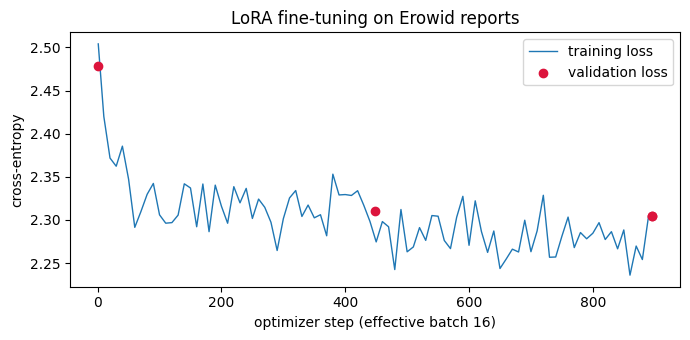


PROMPT (held-out report): The following is a drug experience of someone who took 160 mg of MDMA oral in powder / crystals form, ? ? of Cannabis smoked in ? form and 50 mg of MDMA insufflated in powder / crystals form.

[fine-tuned] MDMA Use: A Trip Report

I've written down notes from a first time try of E and some thoughts/philosophical issues I’ve had since that. I'll start with a 48 hour timeline of what happened when I took the pill or

[base] ---

I took 160mg orally of molly (MDMA) around 11pm. I had taken 2 hits of acid earlier in the day. I wasn't feeling much from the molly at first, but around 12:30

Template-leak check (an earlier run without prompt masking gave 0.976 and 0.040 for the fine-tuned model):
                       context  P(The) base  P(The) fine-tuned
     right after start-of-text       0.0006             0.0007
mid-definition in a DAT answer       0.0000             0.0000


In [9]:
# TASK 1A — training curve, validation loss before/after, and generation from the saved fine-tuned model
import matplotlib.pyplot as plt

hist = json.load(open(ADAPTER_DIR / "log_history.json"))
tr = pd.DataFrame([h for h in hist if "loss" in h])
ev = pd.DataFrame([h for h in hist if "eval_loss" in h])
before = json.load(open(ART_DIR / "eval_before_training.json"))["eval_loss"]
after = json.load(open(ART_DIR / "eval_after_training.json"))["eval_loss"]
print(f"validation loss  base: {before:.4f} (ppl {math.exp(before):.2f})  ->  fine-tuned: {after:.4f} (ppl {math.exp(after):.2f})")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tr["step"], tr["loss"], label="training loss", lw=1)
ax.scatter([0] + ev["step"].tolist(), [before] + ev["eval_loss"].tolist(), color="crimson", zorder=3, label="validation loss")
ax.set_xlabel("optimizer step (effective batch 16)")
ax.set_ylabel("cross-entropy")
ax.set_title("LoRA fine-tuning on Erowid reports")
ax.legend()
plt.tight_layout()
plt.show()

demo = val_ds[0]
demo_prompt = demo["prompt"] + "."
print("\nPROMPT (held-out report):", demo_prompt)
model.eval()
for name, ctx in [("fine-tuned", contextlib.nullcontext()), ("base", model.disable_adapter())]:
    with ctx:
        out = generate(model, tok, [demo_prompt], temperature=1.0, max_new_tokens=60, use_chat=False)[0]
    print(f"\n[{name}] {out.strip()}")

# Template-leak check: probability of "The" where it should be unlikely (base vs fine-tuned)
the_ids = sorted({i for i in (tok.encode(x, add_special_tokens=False)[-1] for x in ["The", " The"])
                  if tok.decode([i]).strip() == "The"})
contexts = {"right after start-of-text": tok.bos_token or tok.eos_token,
            "mid-definition in a DAT answer": format_prompt(tok, DAT_PROMPT, USE_CHAT) + " 1. Love: a feeling of deep affection"}
leak = []
for name, text in contexts.items():
    ids = tok(text, return_tensors="pt", add_special_tokens=False).input_ids.to(model.device)
    row = {"context": name}
    for cond, ctx in [("base", model.disable_adapter()), ("fine-tuned", contextlib.nullcontext())]:
        with ctx, torch.inference_mode():
            p = model(ids).logits[0, -1].float().softmax(-1)
        row[f"P(The) {cond}"] = float(p[the_ids].sum())
    leak.append(row)
print("\nTemplate-leak check (an earlier run without prompt masking gave 0.976 and 0.040 for the fine-tuned model):")
print(pd.DataFrame(leak).round(4).to_string(index=False))

## Task 1B — Reproducibility log

Maintain a structured log of all implementation decisions: complete the provided template and include it in the submitted folder.

For each item in the file template of the reproducibility log released on Canvas, record:

- Whether it was specified in the report?
- What decision you made
- A justification for your decision
- What impact you expect this step could have on the final result if a different decision were made

Example:

Learning rate
- Not specified
- Chose 2e-4
- Because it is a common LoRA default for similar models
- It may affect convergence

10 points are available, awarded based on whether you correctly identify whether a certain decision was specified in the original report, whether your choice was reasonable, whether you justified it with sufficient support, and whether your expectations about the impact of a decision were sensible and well justified.

**Task 1B — reproducibility log:** see `stimuli&outputs/group2_reproducibility_log.txt`. It covers all 17 template items (in the report? / choice / justification ≤50 words / potential impact), plus the evaluation decisions and the run history. The run history records the three Colab runs: the failures we detected (untruncated sampling at T=1.5; template memorisation when the loss included the prompt) and the checks that showed the final run can be trusted.

# Task 2 — Evaluate the effect of fine-tuning and temperature

## Goal

Evaluate how the base model and your fine-tuned model behave under different creativity-oriented evaluation protocols.

The question is not simply whether fine-tuning improves creativity. The question is:

> How do fine-tuning and decoding temperature affect different operationalizations of creativity?

Treat creativity as an operational construct. DAT, CDAT, and the novel-word rubric measure different proxies: a higher score on one proxy is not evidence that a model is creative in a general human sense. Your goal is to analyze when the proxies agree, when they conflict, and what this implies for evaluating LLMs.

You will evaluate:

1. the base model before fine-tuning;
2. your fine-tuned model from Task 1a.

For each model, generate outputs at three temperature values:

- low temperature (0.5)
- medium temperature (1)
- high temperature (1.5)

Use the exact values specified, don't change them: if you use different temperature parameters, you will not receive points for this task.

## Task 2A — DAT: Divergent Association Task

Run the Divergent Association Task following the strategy outlined in Nakajima et al 2026.

The model should generate a list of words that are as semantically different from one another as possible.

For each model and temperature setting:

- generate responses using the template provided by Nakajima et al 2026 in Appendix B.1, repeating the procedure 50 times (this is fewer than the 500 in the original paper to save runtime). Make sure that each iteration doesn't consider previous iterations as context!
- filter invalid responses according to the rules in Nakajima et al's Appendix B.2;
- compute the DAT score, using SBERT representations and following the approach from Nakajima et al 2026;
- in the notebook, output the mean, median, standard deviation, and interquartile range of the 50 DAT values you obtained.


10 points available, awarded for correctly implementing the DAT pipeline (generation, filtering, computation, summary statistics)

In [10]:
# implement the DAT here
# TASK 2A — DAT: generation (50 independent repetitions per model x temperature), filtering and SBERT scoring
# "base" = the same network with the LoRA adapter switched off; "fine-tuned" = adapter on.
def condition(name):
    return model.disable_adapter() if name == "base" else contextlib.nullcontext()


MODEL_NAMES = ["base", "fine-tuned"]


def run_dat(top_k=TOP_K, tag="dat"):
    rows = []
    for mname in MODEL_NAMES:
        for T in TEMPERATURES:
            with condition(mname):
                gens = cached_generate(f"{tag}_{mname}_T{T}", model, tok, [DAT_PROMPT] * N_DAT, T,
                                       MAX_NEW_TOKENS_LIST, USE_CHAT, top_k=top_k)
            for rep, g in enumerate(gens, start=1):
                first7, n_valid, n_items = valid_words(g["output"])
                rows.append({"model": mname, "temperature": T, "repetition_id": rep, "valid words": ", ".join(first7),
                             "n_valid": n_valid, "n_items": n_items, "n_tokens": g["n_tokens"], "finished": g["finished"],
                             "status": drop_reason(g["output"], g["finished"], n_valid),
                             "score": dat_score(first7) if len(first7) == 7 else np.nan, "raw": g["output"]})
    return pd.DataFrame(rows)


dat = run_dat()

# Task-agnostic baseline (Nakajima et al. §3.2): 10 random WordNet nouns, same filter and scoring, 500 times
rng = random.Random(SEED)
rand_dat = []
for _ in range(500):
    w7 = valid_words("\n".join(rng.sample(RANDOM_NOUN_POOL, 10)))[0]
    rand_dat.append(dat_score(w7) if len(w7) == 7 else np.nan)
rand_dat = pd.Series(rand_dat).dropna()

dat_tsv = TSV_DIR / f"{GROUP}_DAT_scores.tsv"
dat[["model", "temperature", "repetition_id", "valid words", "score"]].to_csv(dat_tsv, sep="\t", index=False, na_rep="NA")
print(f"wrote {dat_tsv} ({len(dat)} rows; responses with <7 valid words keep their valid words and score NA)")
print(f"decoding: temperature in {TEMPERATURES}, top_k={TOP_K}, top_p={TOP_P}, max_new_tokens={MAX_NEW_TOKENS_LIST}\n")
print("Response status (scored = at least 7 valid words):")
print(pd.crosstab([dat.model, dat.temperature], dat.status).to_string())
print("\nVerbosity: mean generated tokens / listed items / valid nouns per response")
print(dat.groupby(["model", "temperature"])[["n_tokens", "n_items", "n_valid"]].mean().round(1).to_string())
MIDCAPS = re.compile(r"(?<=[a-z,] )(?:The|A|An|Of|And|Between)\b")
dat["midcaps_per_1k_words"] = [1000 * len(MIDCAPS.findall(t)) / max(len(t.split()), 1) for t in dat.raw]
print("\nDegeneration check: mid-sentence capitalised function words per 1,000 words (e.g. 'or The The'):")
print(dat.groupby(["model", "temperature"]).midcaps_per_1k_words.mean().unstack().round(2).to_string())
print("\nExample responses at T=1.0:")
for mname in MODEL_NAMES:
    r = dat[(dat.model == mname) & (dat.temperature == 1.0)].iloc[0]
    print(f"[{mname}] {r.raw.strip()[:220]!r}\n    -> {r['valid words']} | score {r.score:.1f}")

wrote /content/drive/MyDrive/NLP Take Home Assignment/stimuli&outputs/groupXX_DAT_scores.tsv (300 rows; responses with <7 valid words keep their valid words and score NA)
decoding: temperature in [0.5, 1.0, 1.5], top_k=50, top_p=1.0, max_new_tokens=400

Response status (scored = at least 7 valid words):
status                  cut off at token limit  scored  too few valid nouns
model      temperature                                                     
base       0.5                               0      50                    0
           1.0                               0      50                    0
           1.5                               1      46                    3
fine-tuned 0.5                               0      50                    0
           1.0                               0      50                    0
           1.5                               2      46                    2

Verbosity: mean generated tokens / listed items / valid nouns per response
           

In [11]:
# compute the summary statistics for the DAT in this cell and print them.
# TASK 2A — DAT summary statistics (mean, median, SD, IQR of the 50 DAT values per model x temperature)
dat_summary = dat.groupby(["model", "temperature"]).score.apply(summarize).unstack()
dat_summary.insert(0, "responses", dat.groupby(["model", "temperature"]).size())
dat_summary.insert(1, "share scored", dat_summary["n"] / dat_summary["responses"])
print("DAT score over the responses with at least 7 valid words (n = scored responses out of 50):")
print(dat_summary.round(2).to_string())
print(f"\nRandom-noun baseline (500 lists): mean {rand_dat.mean():.2f}, 95% CI ±{1.96 * rand_dat.std() / np.sqrt(len(rand_dat)):.2f}")

DAT score over the responses with at least 7 valid words (n = scored responses out of 50):
                        responses  share scored     n   mean  median    sd   IQR     Q1     Q3
model      temperature                                                                        
base       0.5                 50          1.00  50.0  77.11   77.03  2.54  2.35  76.20  78.55
           1.0                 50          1.00  50.0  77.08   77.08  2.42  2.55  75.91  78.46
           1.5                 50          0.92  46.0  76.22   76.62  3.16  5.02  73.50  78.52
fine-tuned 0.5                 50          1.00  50.0  75.76   76.13  3.89  3.12  74.41  77.53
           1.0                 50          1.00  50.0  76.04   76.42  3.79  3.96  74.52  78.48
           1.5                 50          0.92  46.0  74.85   75.62  4.02  5.41  72.74  78.15

Random-noun baseline (500 lists): mean 81.12, 95% CI ±0.23


Pairwise contrasts (Welch t-tests, Cohen's d, Benjamini-Hochberg FDR):
     effect                contrast    diff        n       d      p  p_FDR
temperature       base: T1.0 - T0.5 -0.0320 50 vs 50 -0.0129 0.9488 0.9488
temperature       base: T1.5 - T0.5 -0.8895 46 vs 50 -0.3118 0.1340 0.2126
temperature       base: T1.5 - T1.0 -0.8575 46 vs 50 -0.3064 0.1417 0.2126
temperature fine-tuned: T1.0 - T0.5  0.2780 50 vs 50  0.0724 0.7181 0.8079
temperature fine-tuned: T1.5 - T0.5 -0.9107 46 vs 50 -0.2305 0.2627 0.3377
temperature fine-tuned: T1.5 - T1.0 -1.1887 46 vs 50 -0.3049 0.1400 0.2126
fine-tuning T0.5: fine-tuned - base -1.3474 50 vs 50 -0.4102 0.0434 0.2126
fine-tuning T1.0: fine-tuned - base -1.0375 50 vs 50 -0.3263 0.1066 0.2126
fine-tuning T1.5: fine-tuned - base -1.3686 46 vs 46 -0.3789 0.0727 0.2126

Two-way ANOVA on DAT (type II; partial eta^2 = share of variance explained by each factor):
                  sum_sq     df        F  PR(>F)  partial_eta2
C(model)        113.691

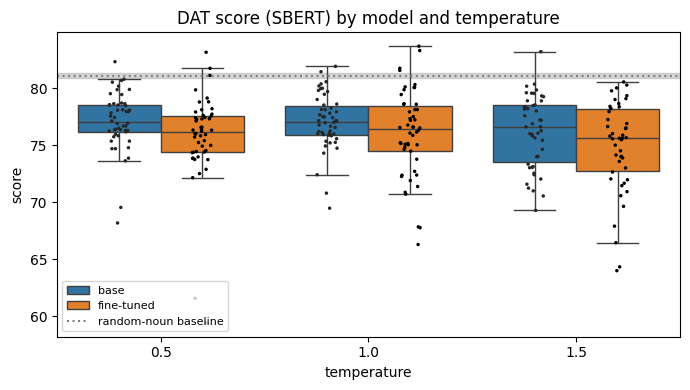

In [12]:
# TASK 2A — analyses for Q2.A1-Q2.A3: pairwise Welch t-tests (BH-FDR), Cohen's d, two-way ANOVA effect sizes, plot
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
import statsmodels.api as sm
import seaborn as sns


def cohens_d(a, b):
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp


def welch(a, b):
    """Welch t-test; NaN when a group has fewer than 2 scored responses."""
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    if len(a) < 2 or len(b) < 2:
        return np.nan, np.nan
    return cohens_d(a, b), stats.ttest_ind(a, b, equal_var=False).pvalue


def fdr(p):
    """Benjamini-Hochberg over the available p-values only (untestable contrasts stay NaN)."""
    p = pd.Series(p, dtype=float)
    out = pd.Series(np.nan, index=p.index)
    if p.notna().any():
        out[p.notna()] = multipletests(p.dropna(), method="fdr_bh")[1]
    return out


def contrasts(df, value):
    """Temperature contrasts within each model and fine-tuning contrasts within each temperature."""
    rows = []
    for m in MODEL_NAMES:
        for t1, t2 in itertools.combinations(TEMPERATURES, 2):
            a = df[(df.model == m) & (df.temperature == t2)][value]
            b = df[(df.model == m) & (df.temperature == t1)][value]
            d, p = welch(a, b)
            rows.append({"effect": "temperature", "contrast": f"{m}: T{t2} - T{t1}", "diff": a.mean() - b.mean(),
                         "n": f"{a.notna().sum()} vs {b.notna().sum()}", "d": d, "p": p})
    for T in TEMPERATURES:
        a = df[(df.model == "fine-tuned") & (df.temperature == T)][value]
        b = df[(df.model == "base") & (df.temperature == T)][value]
        d, p = welch(a, b)
        rows.append({"effect": "fine-tuning", "contrast": f"T{T}: fine-tuned - base", "diff": a.mean() - b.mean(),
                     "n": f"{a.notna().sum()} vs {b.notna().sum()}", "d": d, "p": p})
    out = pd.DataFrame(rows)
    out["p_FDR"] = fdr(out.p)
    return out


def vs_baseline(df, value, baseline):
    """Each model x temperature against the random-noun baseline (Nakajima et al.'s central comparison)."""
    rows = []
    for (m, T), g in df.groupby(["model", "temperature"]):
        d, p = welch(g[value], baseline)
        rows.append({"model": m, "temperature": T, "mean": g[value].mean(), "baseline": baseline.mean(), "d": d, "p": p})
    out = pd.DataFrame(rows)
    out["p_FDR"] = fdr(out.p)
    return out


def anova_effects(df, value):
    d = df.dropna(subset=[value]).assign(T=lambda x: x.temperature.astype(str))
    fit = smf.ols(f"Q('{value}') ~ C(model) * C(T)", data=d).fit()
    a = sm.stats.anova_lm(fit, typ=2)
    a["partial_eta2"] = a["sum_sq"] / (a["sum_sq"] + a.loc["Residual", "sum_sq"])
    return a


dat_contrasts = contrasts(dat, "score")
print("Pairwise contrasts (Welch t-tests, Cohen's d, Benjamini-Hochberg FDR):")
print(dat_contrasts.round(4).to_string(index=False))
print("\nTwo-way ANOVA on DAT (type II; partial eta^2 = share of variance explained by each factor):")
print(anova_effects(dat, "score").round(4).to_string())
print("\nEach condition vs the random-noun baseline:")
print(vs_baseline(dat, "score", rand_dat).round(4).to_string(index=False))
share = dat.assign(ok=dat.score.notna()).groupby(["model", "temperature"]).ok.mean().unstack()
print("\nShare of responses that could be scored (valid output is itself affected by temperature and fine-tuning):")
print(share.round(2).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=dat, x="temperature", y="score", hue="model", ax=ax, fliersize=0)
sns.stripplot(data=dat, x="temperature", y="score", hue="model", dodge=True, ax=ax, color="k", size=2.5, legend=False)
lo, hi = rand_dat.mean() - 1.96 * rand_dat.std() / np.sqrt(len(rand_dat)), rand_dat.mean() + 1.96 * rand_dat.std() / np.sqrt(len(rand_dat))
ax.axhspan(lo, hi, color="grey", alpha=0.3)
ax.axhline(rand_dat.mean(), color="grey", ls=":", label="random-noun baseline")
ax.set_title("DAT score (SBERT) by model and temperature")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

Answer the following questions, providing your answer in the same cell as the question, directly below it.

Q2.A1: Does temperature scaling affect DAT scores for the base and fine-tuned model? Are your results consistent with Nakajima et al? (3 points)

---
**Answer.**

Barely. Mean DAT is flat for the base model (77.1, 77.1, 76.2 at T = 0.5/1/1.5) and for the fine-tuned model (75.8, 76.0, 74.9). No temperature contrast survives FDR correction (|d| ≤ 0.31), and temperature explains 1.8% of the variance (two-way ANOVA, p = .075).

What temperature changes is the spread (base SD 2.5 → 3.2) and validity. At T = 1.5, 8% of lists become unscorable; with untruncated sampling, 90–98% do.

This is consistent with Nakajima et al.: temperature effects are small and family-specific, and every condition stays below the random-noun baseline (81.1; d = −1.5 to −2.3). Some of their open models also gave no extractable answers at T = 1.5. Higher temperature does not make lists more divergent; it makes them less reliable.

Q2.A2: Does fine-tuning affect DAT scores at various temperature levels? (3 points)

---
**Answer.**

Slightly, and in the same direction at every temperature. Fine-tuning lowers DAT by 1.3, 1.0 and 1.4 points at T = 0.5/1/1.5 (d = −0.41, −0.33, −0.38). No single contrast survives FDR correction, but the pooled model effect is significant (ANOVA F = 10.1, p = .002, partial η² = .034). There is no interaction (partial η² < .001): fine-tuning shifts the whole distribution down without changing how temperature acts. The fine-tuned model is also less consistent (SD 3.8–4.0 vs 2.4–3.2), while both models remain equally scorable (100/100/92%).

This effect depends heavily on training details. In an earlier run where the loss also covered the prompt, the fine-tuned model degenerated ("The The The…") and lost 30–40% of its lists. That would have dominated any comparison.

Q2.A3: Are effects of fine-tuning larger or smaller than the effects of temperature scaling? Provide an explanation of how you compared the two and determined which was strongest. (4 points)

---
**Answer.**

On DAT scores, fine-tuning has the larger effect, but both are small. We compared them in three ways:
1. Variance explained in a two-way ANOVA (model × temperature, type II): fine-tuning partial η² = .034 (p = .002) vs temperature .018 (p = .075); interaction ≈ 0.
2. Standardised pairwise contrasts (Welch t-tests, Cohen's d, BH-FDR): fine-tuning |d| = 0.33–0.41 at every temperature; temperature |d| = 0.01–0.31.
3. A reference scale: both effects are dwarfed by the gap to the random-noun baseline (d ≈ −1.5 to −2.3).

Temperature dominates validity rather than scores. Combined with the decoding choice, it decides whether answers are scorable at all: 92% at T = 1.5 with top-k 50, but 2–10% without truncation. Scores exist only for valid lists, so high-temperature comparisons are conditioned on the surviving answers.

## Task 2B — CDAT: Conditional Divergent Association Task

Run the Conditional Divergent Association Task from Nakajima et al 2026.

In CDAT, the model should generate words that are semantically diverse but still appropriate for a cue word or context.

For each model and temperature setting:

- generate responses for the provided 50 cue words (sampled from the 539 words used by Nakajima et al 2026), using the template indicated in Appendix C.1, making sure that each generation doesn't consider previous generations as context;
- compute novelty as average pairwise semantic distance among valid generated words. Compute appropriateness as average semantic similarity between the cue and each valid generated word. Treat CDAT as novelty conditional on meeting a minimal appropriateness criterion. In your report, do not rely only on the scalar score: also visualize novelty against appropriateness.
- in the notebook, output the mean, median, standard deviation, and interquartile range of novelty, appropriateness, and CDAT scores for the given 50 cue words.

10 points available, awarded for correctly implementing the CDAT pipeline (generation, filtering, computation, summary statistics)

In [13]:
# implement the CDAT here
# TASK 2B — CDAT: generation for the 50 provided cue words (one independent generation per cue x model x temperature)
def run_cdat(top_k=TOP_K, tag="cdat"):
    rows = []
    for mname in MODEL_NAMES:
        for T in TEMPERATURES:
            with condition(mname):
                gens = cached_generate(f"{tag}_{mname}_T{T}", model, tok, [CDAT_PROMPT.format(cue=c) for c in CUES],
                                       T, MAX_NEW_TOKENS_LIST, USE_CHAT, top_k=top_k)
            for cue, g in zip(CUES, gens):
                first7, n_valid, n_items = valid_words(g["output"])
                rows.append({"model": mname, "temperature": T, "cue word": cue, "valid words": ", ".join(first7),
                             "words": first7, "n_valid": n_valid, "n_items": n_items, "n_tokens": g["n_tokens"],
                             "status": drop_reason(g["output"], g["finished"], n_valid), "raw": g["output"]})
    return pd.DataFrame(rows)


cdat = run_cdat()
print("Response status (scored = at least 7 valid words):")
print(pd.crosstab([cdat.model, cdat.temperature], cdat.status).to_string())
print("\nVerbosity: mean generated tokens / listed items / valid nouns per response")
print(cdat.groupby(["model", "temperature"])[["n_tokens", "n_items", "n_valid"]].mean().round(1).to_string())

Response status (scored = at least 7 valid words):
status                  scored  too few valid nouns
model      temperature                             
base       0.5              47                    3
           1.0              47                    3
           1.5              49                    1
fine-tuned 0.5              50                    0
           1.0              50                    0
           1.5              48                    2

Verbosity: mean generated tokens / listed items / valid nouns per response
                        n_tokens  n_items  n_valid
model      temperature                            
base       0.5             231.9     15.4     10.6
           1.0             250.8     15.4     10.8
           1.5             292.0     17.9     10.9
fine-tuned 0.5             198.1     12.5     10.8
           1.0             222.5     14.9     11.0
           1.5             279.0     16.1      9.9


In [14]:
# compute novelty and appropriateness
# TASK 2B — novelty, appropriateness, appropriateness gate and CDAT score
# novelty         = DAT formula on the first 7 valid words (100 x mean pairwise cosine distance)
# appropriateness = 100 x mean(1 + cos(cue, word)) over the same 7 words
ok = cdat.n_valid >= 7
cdat["novelty"] = [dat_score(w) if k else np.nan for w, k in zip(cdat.words, ok)]
cdat["appropriateness"] = [appropriateness_score(c, w) if k else np.nan
                           for c, w, k in zip(cdat["cue word"], cdat.words, ok)]

# Random baseline (Nakajima et al. §4.2): 10 random WordNet nouns per list, independent of the cue.
# 100 lists per cue: the first 10 per cue (500 lists, as in the paper) feed the model-level t-test,
# all 100 give each cue's 95th-percentile appropriateness (used for the per-row gate).
rng = random.Random(SEED)
rand_rows = []
for cue in CUES:
    for i in range(100):
        w7 = valid_words("\n".join(rng.sample(RANDOM_NOUN_POOL, 10)))[0]
        if len(w7) == 7:
            rand_rows.append({"cue word": cue, "i": i, "novelty": dat_score(w7), "appropriateness": appropriateness_score(cue, w7)})
rand_cdat = pd.DataFrame(rand_rows)
rand_gate_sample = rand_cdat[rand_cdat.i < 10]
cue_threshold = rand_cdat.groupby("cue word").appropriateness.quantile(0.95)

# Model-level gate: Welch t-test of per-cue appropriateness vs Random, BH-FDR over the 6 model x temperature tests,
# pass if adjusted p < .001 and the mean appropriateness is higher than Random's.
gate_rows = []
for (mname, T), g in cdat.groupby(["model", "temperature"]):
    a = g.appropriateness.dropna()
    p = stats.ttest_ind(a, rand_gate_sample.appropriateness, equal_var=False).pvalue if len(a) > 1 else 1.0
    gate_rows.append({"model": mname, "temperature": T, "n_valid_cues": len(a), "mean_app": a.mean(),
                      "random_mean_app": rand_gate_sample.appropriateness.mean(), "p": p})
gate = pd.DataFrame(gate_rows)
gate["p_FDR"] = multipletests(gate.p, method="fdr_bh")[1]
gate["model_passes"] = (gate.p_FDR < 0.001) & (gate.mean_app > gate.random_mean_app)
print(gate.round(5).to_string(index=False))

# Per-row gate (the TSV needs yes/no per cue): model x temperature passes the model-level gate AND the list has
# 7 valid words AND its appropriateness exceeds that cue's 95th-percentile random appropriateness.
cdat = cdat.merge(gate[["model", "temperature", "model_passes"]], on=["model", "temperature"])
cdat["cue_threshold"] = cdat["cue word"].map(cue_threshold)
cdat["passed gate"] = np.where(cdat.model_passes & ok.values & (cdat.appropriateness > cdat.cue_threshold), "yes", "no")
cdat["score"] = np.where(cdat["passed gate"] == "yes", cdat.novelty, np.nan)   # CDAT = novelty conditional on the gate

cdat_tsv = TSV_DIR / f"{GROUP}_CDAT_scores.tsv"
cdat[["model", "temperature", "cue word", "valid words", "score", "novelty", "appropriateness", "passed gate"]].to_csv(
    cdat_tsv, sep="\t", index=False, na_rep="NA")
print(f"\nwrote {cdat_tsv} ({len(cdat)} rows)")
print("rows passing the gate:")
print(pd.crosstab([cdat.model, cdat.temperature], cdat["passed gate"]).to_string())

     model  temperature  n_valid_cues  mean_app  random_mean_app   p  p_FDR  model_passes
      base          0.5            47 133.38509        119.81027 0.0    0.0          True
      base          1.0            47 132.05236        119.81027 0.0    0.0          True
      base          1.5            49 130.82138        119.81027 0.0    0.0          True
fine-tuned          0.5            50 133.41383        119.81027 0.0    0.0          True
fine-tuned          1.0            50 129.62841        119.81027 0.0    0.0          True
fine-tuned          1.5            48 128.72717        119.81027 0.0    0.0          True

wrote /content/drive/MyDrive/NLP Take Home Assignment/stimuli&outputs/groupXX_CDAT_scores.tsv (300 rows)
rows passing the gate:
passed gate             no  yes
model      temperature         
base       0.5           8   42
           1.0          10   40
           1.5           9   41
fine-tuned 0.5           5   45
           1.0          13   37
           1.5   

In [15]:
# compute the summary statistics for the CDAT in this cell and print them.
# TASK 2B — summary statistics of novelty, appropriateness and CDAT over the 50 cue words
rows = []
for (mname, T), g in cdat.groupby(["model", "temperature"]):
    for metric, vals in [("novelty", g.novelty), ("appropriateness", g.appropriateness), ("CDAT", g.score)]:
        rows.append({"model": mname, "temperature": T, "metric": metric, **summarize(vals).to_dict()})
cdat_summary = pd.DataFrame(rows).set_index(["metric", "model", "temperature"]).sort_index()
print("Novelty / appropriateness over cues with at least 7 valid words; CDAT over cues that pass the gate (n = cues):")
print(cdat_summary.round(2).to_string())
print(f"\nRandom baseline: novelty {rand_cdat.novelty.mean():.2f}, appropriateness {rand_cdat.appropriateness.mean():.2f}")

Novelty / appropriateness over cues with at least 7 valid words; CDAT over cues that pass the gate (n = cues):
                                           n    mean  median    sd    IQR      Q1      Q3
metric          model      temperature                                                   
CDAT            base       0.5          42.0   68.89   69.17  5.71   7.58   65.14   72.72
                           1.0          40.0   70.46   71.23  5.25   5.74   68.15   73.89
                           1.5          41.0   72.02   72.37  4.02   4.42   70.68   75.09
                fine-tuned 0.5          45.0   70.00   70.64  6.05   7.73   66.60   74.34
                           1.0          37.0   71.18   72.49  5.15   5.69   69.22   74.90
                           1.5          38.0   72.78   72.46  5.21   7.24   69.24   76.48
appropriateness base       0.5          47.0  133.39  133.90  8.80  10.73  128.24  138.97
                           1.0          47.0  132.05  132.10  8.59   9.72  126.

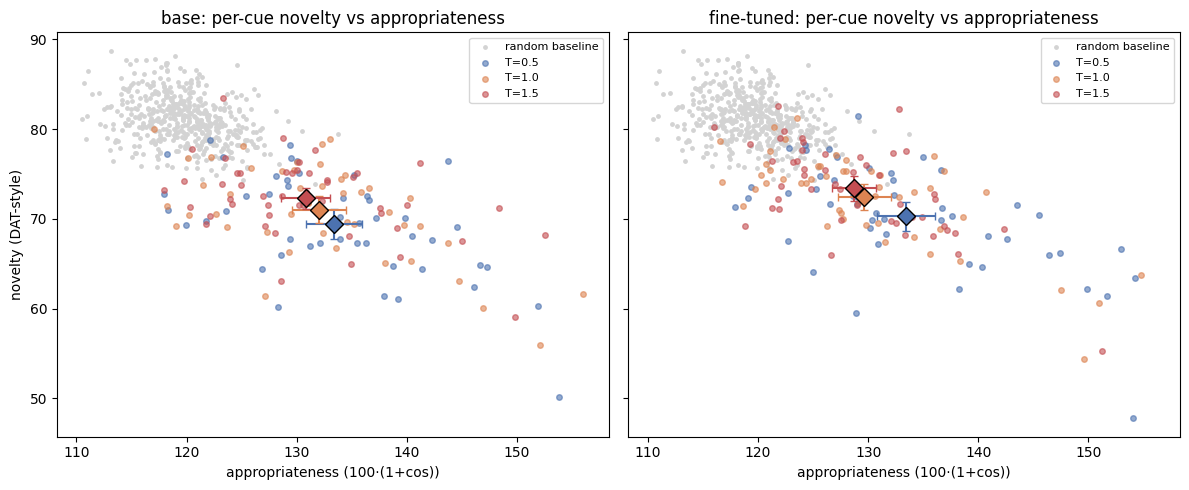

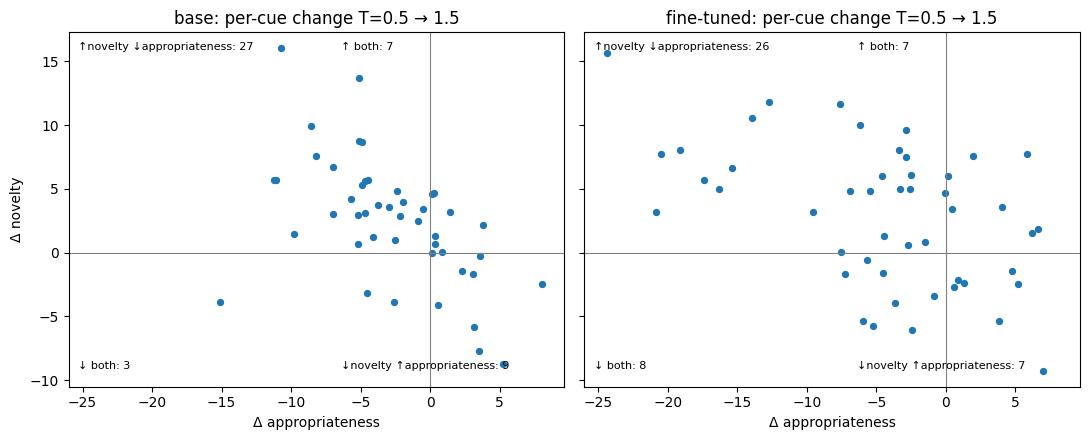

In [16]:
# TASK 2B — novelty vs appropriateness: 2D landscape per condition (Q2.B2)
pal = {0.5: "#4C72B0", 1.0: "#DD8452", 1.5: "#C44E52"}
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, mname in zip(axes, MODEL_NAMES):
    ax.scatter(rand_gate_sample.appropriateness, rand_gate_sample.novelty, s=6, color="lightgrey", label="random baseline")
    for T in TEMPERATURES:
        g = cdat[(cdat.model == mname) & (cdat.temperature == T)].dropna(subset=["novelty"])
        ax.scatter(g.appropriateness, g.novelty, s=16, alpha=0.6, color=pal[T], label=f"T={T}")
        mx, my = g.appropriateness.mean(), g.novelty.mean()
        ex, ey = 1.96 * g.appropriateness.sem(), 1.96 * g.novelty.sem()
        ax.errorbar(mx, my, xerr=ex, yerr=ey, color=pal[T], marker="D", ms=9, mec="k", capsize=3)
    ax.set_title(f"{mname}: per-cue novelty vs appropriateness")
    ax.set_xlabel("appropriateness (100·(1+cos))")
    axes[0].set_ylabel("novelty (DAT-style)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Paired per-cue change from T=0.5 to T=1.5
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, mname in zip(axes, MODEL_NAMES):
    w = cdat[cdat.model == mname].pivot(index="cue word", columns="temperature", values=["novelty", "appropriateness"])
    dN = w["novelty"][1.5] - w["novelty"][0.5]
    dA = w["appropriateness"][1.5] - w["appropriateness"][0.5]
    ax.scatter(dA, dN, s=18)
    ax.axhline(0, color="grey", lw=0.8)
    ax.axvline(0, color="grey", lw=0.8)
    for q, (sx, sy) in {"↑novelty ↓appropriateness": (-1, 1), "↑ both": (1, 1), "↓ both": (-1, -1), "↓novelty ↑appropriateness": (1, -1)}.items():
        n = ((np.sign(dA) == sx) & (np.sign(dN) == sy)).sum()
        ax.annotate(f"{q}: {n}", xy=(0.02 if sx < 0 else 0.55, 0.95 if sy > 0 else 0.05), xycoords="axes fraction", fontsize=8)
    ax.set_title(f"{mname}: per-cue change T=0.5 → 1.5")
    ax.set_xlabel("Δ appropriateness")
    axes[0].set_ylabel("Δ novelty")
plt.tight_layout()
plt.show()

In [17]:
# TASK 2B — statistics for the trade-off (Q2.B2): mixed models with a random intercept per cue, correlations
d = cdat.dropna(subset=["novelty"]).rename(columns={"cue word": "cue"}).assign(T=lambda x: x.temperature)
for metric in ["novelty", "appropriateness"]:
    fit = smf.mixedlm(f"{metric} ~ T * C(model, Treatment('base'))", d, groups=d["cue"]).fit(reml=True)
    print(f"--- mixed model: {metric} ~ temperature x model + (1 | cue)")
    print(fit.summary().tables[1].round(4).to_string())
print("\nSpearman correlation between novelty and appropriateness across cues, per condition (n = scored cues):")
corr = d.groupby(["model", "temperature"]).apply(
    lambda g: pd.Series({"n": len(g), **dict(zip(["rho", "p"], stats.spearmanr(g.novelty, g.appropriateness)
                                                  if len(g) >= 5 else (np.nan, np.nan)))}))
print(corr.round(4).to_string())
print("\nPairwise contrasts (Welch, BH-FDR):")
for metric in ["novelty", "appropriateness"]:
    print(f"[{metric}]")
    print(contrasts(cdat, metric).round(4).to_string(index=False))

--- mixed model: novelty ~ temperature x model + (1 | cue)
                                              Coef. Std.Err.       z  P>|z|  [0.025  0.975]
Intercept                                    68.387    0.993  68.895  0.000  66.442  70.333
C(model, Treatment('base'))[T.fine-tuned]     0.581    1.184   0.491  0.623  -1.740   2.903
T                                             2.470    0.780   3.168  0.002   0.942   3.998
T:C(model, Treatment('base'))[T.fine-tuned]   0.586    1.095   0.535  0.593  -1.561   2.733
Group Var                                    13.170    0.924                               
--- mixed model: appropriateness ~ temperature x model + (1 | cue)
                                               Coef. Std.Err.       z  P>|z|   [0.025   0.975]
Intercept                                    134.677    1.463  92.085  0.000  131.810  137.544
C(model, Treatment('base'))[T.fine-tuned]      0.619    1.511   0.410  0.682   -2.342    3.580
T                                    

In [18]:
# TASK 2B — word-level diagnostics of the generated lists (Q2.B1)
def shares_stem(cue, w):
    return w != cue and (w.startswith(cue[:5]) or cue.startswith(w[:5]) or cue in w or w in cue)


diag = []
for (mname, T), g in cdat.groupby(["model", "temperature"]):
    allw = [w for ws in g.words for w in ws]
    cnt = collections.Counter(allw)
    diag.append({"model": mname, "temperature": T,
                 "lists with cue itself": sum(c in ws for c, ws in zip(g["cue word"], g.words)),
                 "lists with cue-derived word": sum(any(shares_stem(c, w) for w in ws) for c, ws in zip(g["cue word"], g.words)),
                 "distinct words / total": f"{len(cnt)}/{len(allw)}",
                 "most frequent words": ", ".join(f"{w}({n})" for w, n in cnt.most_common(8))})
print(pd.DataFrame(diag).to_string(index=False))
print("\nExample lists (cue -> first 7 valid words):")
for mname in MODEL_NAMES:
    for T in TEMPERATURES:
        g = cdat[(cdat.model == mname) & (cdat.temperature == T)]
        print(f"[{mname}, T={T}] " + " | ".join(f"{c}: {v}" for c, v in zip(g["cue word"][:3], g["valid words"][:3])))

     model  temperature  lists with cue itself  lists with cue-derived word distinct words / total                                                                                    most frequent words
      base          0.5                      6                            4                272/337    symphony(6), dream(4), education(4), harmony(4), rainbow(4), serenity(4), triumph(3), innovation(3)
      base          1.0                      6                            4                286/338             technology(5), art(5), melody(5), symphony(4), jungle(3), equation(3), chaos(3), galaxy(3)
      base          1.5                      4                            2                310/343                   symphony(5), river(4), harmony(3), crime(2), love(2), sympathy(2), space(2), ruin(2)
fine-tuned          0.5                      5                            5                299/350          symphony(6), dream(5), anarchy(4), euphoria(4), harmony(3), technology(3), quilt(3),

Answer the following questions, providing your answer in the same cell as the question, directly below it.

Q2.B1: look at the generated words. Do you notice any particular pattern that raise concerns about the CDAT as an evaluation of creativity? (3 points)

---
**Answer.**

Yes:
- **Stock words:** "creative" stock words recur regardless of the cue. "Symphony" appears in 27 lists across 14 unrelated cues (vinegar, effluent, patrolman, desk…), and harmony, dream, chaos and anarchy behave the same way. Novelty therefore partly reflects a fixed repertoire rather than cue-driven thinking.
- **Cue echoing:** 23 of 300 lists contain the cue itself, which trivially inflates appropriateness.
- **Form over meaning:** "duck" → duckling, dusk, duct, buck (spelling neighbours), and the fine-tuned model answered "associate" with an alphabetical run (anarchy, altruism, ambition, apathy, audacity…).
- **Antonyms and sense-switching:** accomplishment → failure, obstacle; bond → chain, debt, prison. This is a cheap way to maximise distance while staying "associated".
- **A leaky filter:** adjectives and verbs (mediocre, frozen, speak) pass because WordNet lists rare noun senses.

Single-word SBERT similarity measures topical relatedness, not whether a word is a meaningful, apt response.

Q2.B2: do you observe a trade-off between novelty and appropriateness when increasing the temperature? the summary statistics may not be enough to answer this, it's up to you to conduct the right analysis or use the best visualizations to determine this. (7 points)

---
**Answer.**

Yes, a modest but consistent trade-off. In mixed models with a random intercept per cue, each unit of temperature raises novelty by 2.5 points (p = .002) and lowers appropriateness by 2.3 (p = .020), more steeply for the fine-tuned model (interaction −2.4, p = .087).

From T = 0.5 to 1.5, novelty rises in both models (d ≈ 0.57, p_FDR = .03); appropriateness falls by 2.6 (base, n.s.) and 4.7 points (fine-tuned, d = −0.56).

Per cue, 26 of 45 (base) and 26 of 48 (fine-tuned) cues gain novelty while losing appropriateness; the two changes correlate at r = −0.49. Within each condition, the measures are also negatively correlated across cues (ρ = −0.30 to −0.60).

In the 2D plot the means drift toward the random baseline. The rising scalar CDAT (68.9 → 72.0) hides this cost.

## Task 2C — Novel-word generation task

This task is inspired by work on lexical creativity and lexical proficiency, see Ciaccio et al 2025. The goal is to test whether the model can invent plausible new words for novel concepts. For the following five prompts, the model should generate **one invented word**: you will evaluate not only whether the model produces something new, but whether the invented word is *good*. The evaluation has to be conducetd by group members. The goal is not to have a high score, but to provide a justified evaluation.

## Novel-word prompts

1. Invent a single new English noun for the feeling of briefly understanding a dream just as it disappears from memory. Generate only a single output word.


2. Invent a single new English noun for the memory of a smell that causes a sudden sadness. Generate only a single output word.


3. Invent a single new English verb for becoming aware of tiny bodily sensations after hearing someone describe them. Generate only a single output word.


4. Invent a single new English noun for the feeling that music temporarily changes the temperature you perceive. Generate only a single output word.


5. Invent a single new English verb for greeting someone emphatically only to realize you didn't know them at all. Generate only a single output word

Run this task for:

- the base model;
- your fine-tuned model;
- all three temperature settings.

## Novel-word evaluation rubric

Use the following rubric to guide your evaluation of each generated word.

| Criterion | Score | Description |
|---|---:|---|
| Novelty | 0–2 | 0 = existing/common word; 1 = minor variant of an existing word; 2 = clearly novel or rare formation |
| Morphological plausibility | 0–2 | 0 = random string; 1 = somewhat word-like; 2 = plausible English word formation |
| Interpretability | 0–2 | 0 = impossible to infer meaning; 1 = meaning partly recoverable; 2 = meaning recoverable from form|
| Usefulness / memorability | 0–2 | 0 = unusable; 1 = somewhat usable; 2 = memorable and potentially useful |

You may use automatic checks to support your scoring, such as dictionary lookup or edit distance to existing words, but the final judgment should be justified qualitatively: justify every choice with one short sentence.

Based on how many points each prompt scores under different temperature parameters and fine-tuning, answer the following question:

Based on this small diagnostic sample, what patterns do you observe in relation to fine-tuning and temperature? Do not generalize beyond the five prompts unless you add more items. 10 points available.

### Task 2C — code: novel-word generation and automatic support checks

Each of the five prompts is given verbatim, with one independent sample per prompt × model × temperature (seed 111). The models rarely obey "generate only a single output word": they usually answer in a sentence (*I suggest the word "Fleetinglynd" …*). The invented word is therefore extracted in this order: (1) the first quoted or emphasised word or short phrase; (2) a word introduced by "noun/verb/word/term"; (3) a leading `Word:` definition pattern; (4) a single-word first line; (5) a short first line of at most three words (e.g. "Sadness Aura"); (6) the first word. The raw answer is kept next to it, together with an instruction-compliance flag.

The automatic checks (dictionary/WordNet membership, nearest existing word with edit distance, transparent parts) only *support* the human scoring. The rubric scores and justifications in `group2_novelWord_scoring.tsv` are filled in by the group members.

In [19]:
# TASK 2C — novel-word generation (5 prompts x 2 models x 3 temperatures) + automatic support checks
from rapidfuzz import process, distance

_W = r"[A-Za-z][A-Za-z-]+"
_QUOTED = re.compile(r"[\"“”*]+\s*(" + _W + r"(?: " + _W + r"){0,2})[.,!?]?\s*[\"“”*]+")
_INTRO = re.compile(r"\b(?:word|noun|verb|term)\b\s*(?:is|would be|:)?\s*[\"“']?(" + r"[A-Za-z][A-Za-z-]{2,}" + r")")
_LEADING = re.compile(r"^\s*(" + _W + r"(?: " + _W + r")?)\s*:")
STOP = {"the", "a", "an", "i", "is", "of", "to", "for", "this", "that", "new", "english", "noun", "verb", "word"}


def extract_invented(text):
    """Return (invented word or phrase, rule used)."""
    t = text.replace("**", "*").strip()
    first = next((l.strip() for l in t.splitlines() if l.strip()), "")
    m = _QUOTED.search(t)
    if m:
        return m.group(1), "quoted"
    m = _INTRO.search(t)
    if m and m.group(1).lower() not in STOP:
        return m.group(1), "after noun/verb/word"
    m = _LEADING.match(first)
    if m:
        return m.group(1), "Word: definition"
    if re.fullmatch(r"\W*[A-Za-z][A-Za-z'-]*\W*", first):
        return re.sub(r"[^A-Za-z'-]", "", first), "single-word line"
    short = re.sub(r"[^A-Za-z' -]", "", first).strip()
    if 0 < len(short.split()) <= 3:
        return short, "short answer line"
    m = re.search(r"[A-Za-z][A-Za-z'-]*", first)
    return (m.group(0) if m else ""), "first word (fallback)"


PREFIXES = ["mis", "dis", "un", "re", "pre", "trans", "sub", "inter", "over", "olfact", "therm", "sono", "somat"]
SUFFIXES = ["ness", "ity", "tion", "ment", "ence", "ance", "ia", "ize", "ise", "ify", "ate", "esque", "ous", "ic", "ism"]


def transparent_parts(word):
    """Crude morphological hint: a split into two dictionary words (e.g. dream+fade) and recognisable affixes."""
    w = word.lower().replace("-", "")
    split = next((f"{w[:i]}+{w[i:]}" for i in range(3, len(w) - 2) if w[:i] in DICTIONARY and w[i:] in DICTIONARY), "")
    affixes = [a + "-" for a in PREFIXES if w.startswith(a) and len(w) - len(a) >= 4] + \
              ["-" + a for a in SUFFIXES if w.endswith(a) and len(w) - len(a) >= 4]
    return split, ",".join(affixes)


novel_rows = []
for mname in MODEL_NAMES:
    for T in TEMPERATURES:
        with condition(mname):
            gens = cached_generate(f"novel_{mname}_T{T}", model, tok, NOVEL_PROMPTS, T, MAX_NEW_TOKENS_WORD, USE_CHAT)
        for i, (p, g) in enumerate(zip(NOVEL_PROMPTS, gens), start=1):
            word, rule = extract_invented(g["output"])
            core = max(re.findall(r"[A-Za-z][A-Za-z-]*", word) or [""], key=len)
            lw = core.lower()
            nearest = [(v, dd) for v, dd, _ in process.extract(lw, sorted(DICTIONARY), scorer=distance.Levenshtein.distance,
                                                              limit=2) if v != lw] if lw else [("", np.nan)]
            split, affixes = transparent_parts(core)
            novel_rows.append({"model": mname, "temperature": T, "prompt": f"{i}. {p}", "output": word,
                               "extraction rule": rule,
                               "obeyed 'single word'": bool(re.fullmatch(r"\W*[A-Za-z][A-Za-z'-]*\W*", g["output"].strip())),
                               "existing word": lw in DICTIONARY, "nearest existing word": nearest[0][0],
                               "edit distance": nearest[0][1], "two-word split": split, "affixes": affixes,
                               "raw output": g["output"].strip()})
novel = pd.DataFrame(novel_rows)

score_cols = ["novelty", "morphology", "interpretability", "usefulness", "justification"]
score_tsv = TSV_DIR / f"{GROUP}_novelWord_scoring.tsv"
already_scored = score_tsv.exists() and pd.read_csv(score_tsv, sep="\t").reindex(columns=score_cols).notna().any().any()
if already_scored:
    print(f"{score_tsv} already contains the group's scores - not overwritten")
else:
    novel.assign(**{c: "" for c in score_cols})[["model", "temperature", "prompt", "output"] + score_cols].to_csv(
        score_tsv, sep="\t", index=False)
    print(f"wrote {score_tsv}: invented words filled in, score columns left for the group's evaluation")
auto_tsv = TSV_DIR / f"{GROUP}_novelWord_autochecks.tsv"
novel.to_csv(auto_tsv, sep="\t", index=False)
print(f"wrote {auto_tsv}\n")
with pd.option_context("display.max_colwidth", 70, "display.width", 250):
    print(novel.assign(prompt=novel.prompt.str[:2])[["model", "temperature", "prompt", "output", "extraction rule",
                                                       "obeyed 'single word'", "existing word", "nearest existing word",
                                                       "edit distance", "two-word split", "affixes"]].to_string(index=False))
    print("\nRaw answers:")
    for _, r in novel.iterrows():
        print(f"[{r.model}, T={r.temperature}, prompt {r.prompt[:1]}] {r['raw output'][:160]!r}")

wrote /content/drive/MyDrive/NLP Take Home Assignment/stimuli&outputs/groupXX_novelWord_scoring.tsv: invented words filled in, score columns left for the group's evaluation
wrote /content/drive/MyDrive/NLP Take Home Assignment/stimuli&outputs/groupXX_novelWord_autochecks.tsv

     model  temperature prompt                output  extraction rule  obeyed 'single word'  existing word nearest existing word  edit distance         two-word split       affixes
      base          0.5     1. Fleetingcomprehension           quoted                 False          False       incomprehension              6 fleeting+comprehension              
      base          0.5     2.        Olfactosadness           quoted                 False          False           factualness              5                        olfact-,-ness
      base          0.5     3.         quivercognize           quoted                 False          False            ciceronize              5         quiver+cognize          -ize

In [20]:
# TASK 2C — aggregate the group's rubric scores (re-run this cell after filling in group2_novelWord_scoring.tsv)
scored = pd.read_csv(TSV_DIR / f"{GROUP}_novelWord_scoring.tsv", sep="\t")
crit = ["novelty", "morphology", "interpretability", "usefulness"]
if scored[crit].isna().all().all():
    print("Rubric scores not filled in yet: the group members still have to score the 30 outputs.")
else:
    scored["total"] = scored[crit].sum(axis=1)
    print("Mean points per criterion and total (max 8) by model x temperature:")
    print(scored.groupby(["model", "temperature"])[crit + ["total"]].mean().round(2).to_string())
    print("\nTotal points per prompt:")
    print(scored.assign(p=scored.prompt.str[:1]).pivot_table(index="p", columns=["model", "temperature"], values="total").to_string())

Rubric scores not filled in yet: the group members still have to score the 30 outputs.


**[TO BE WRITTEN BY THE GROUP after scoring the 30 outputs in `group2_novelWord_scoring.tsv`. Re-run the aggregation cell above first and base the answer on your point totals per prompt, model and temperature.]**

Automatic observations to check against your scores (not a substitute for them):
- **No output obeys "a single word":** every answer adds an explanation.
- **The base model reuses coinages across temperatures:** Fleetingcomprehension ×3, Introduced ×3, Musicalthermia ×2, quivercognize ×2.
- **The fine-tuned model varies more:** 12 vs 8 distinct coinages in 15 cells (Dreamfade → Dreamgleam → Dreamgleamer), but also repeats Misgreet ×3.
- **Fine-tuned coinages lean on transparent compounding and affixes** (Dreamfade, Odorsadness, Misgreet). Base coinages are longer blends (Fleetingcomprehension, Olfactosadness).
- **At T = 1.5 forms get less transparent** (Olfactiliments, Musiculse, Dreamgleamer).
- **"Introduced" is an existing word:** the automatic dictionary check misses it because it is inflected.

### Task 2D — supporting analyses: decoding sensitivity and cross-task comparison

**Decoding sensitivity.** All results above use Hugging Face's default sampling (top-k 50) with only the temperature varied. To see whether high temperature brings *creativity or noise*, DAT and CDAT are repeated with **untruncated sampling** (top-k disabled: every vocabulary token can be drawn). Prompts and seeds are identical; only the truncation differs. If higher scores at T=1.5 were genuine creativity, they should survive this change. If they are noise, the share of usable answers should collapse.

**Cross-task table.** For each model × temperature, one row per condition puts together the operationalisations of creativity used in this assignment (DAT, CDAT novelty/appropriateness/gate, novel-word automatic checks, and the group's rubric totals once filled in), so that agreement and conflict between the proxies can be read directly.

     model  temperature        decoding  DAT scored  DAT mean  DAT degenerate  CDAT scored  CDAT novelty  CDAT appropriateness
      base          0.5 top-k 50 (main)        1.00    77.108            0.00         0.94        69.424               133.385
      base          1.0 top-k 50 (main)        1.00    77.076            0.00         0.94        71.028               132.052
      base          1.5 top-k 50 (main)        0.92    76.218            0.00         0.98        72.284               130.821
fine-tuned          0.5 top-k 50 (main)        1.00    75.760            0.00         1.00        70.287               133.414
fine-tuned          1.0 top-k 50 (main)        1.00    76.038            0.00         1.00        72.444               129.628
fine-tuned          1.5 top-k 50 (main)        0.92    74.850            0.00         0.96        73.376               128.727
      base          0.5     untruncated        1.00    77.108            0.00         0.94        69.424       

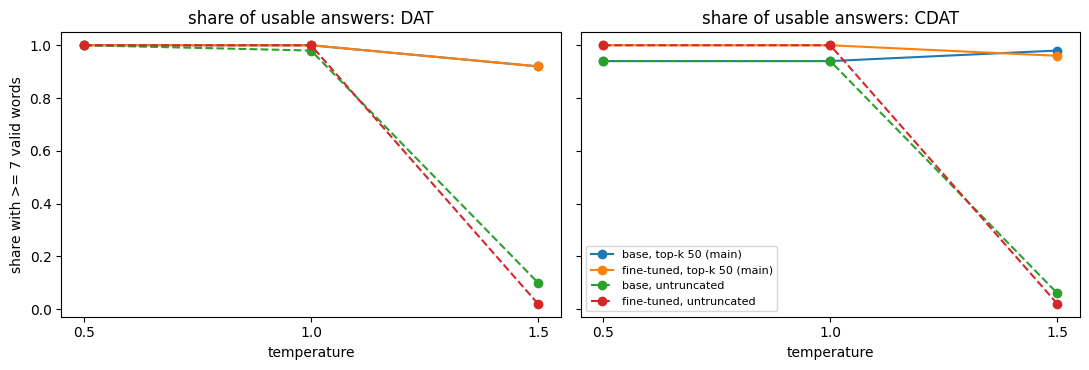

In [21]:
# TASK 2D — decoding sensitivity: the same DAT/CDAT prompts and seeds with untruncated sampling (top_k disabled)
dat_sens = run_dat(top_k=SENSITIVITY_TOP_K, tag="dat")
cdat_sens = run_cdat(top_k=SENSITIVITY_TOP_K, tag="cdat")
ok_s = cdat_sens.n_valid >= 7
cdat_sens["novelty"] = [dat_score(w) if k else np.nan for w, k in zip(cdat_sens.words, ok_s)]
cdat_sens["appropriateness"] = [appropriateness_score(c, w) if k else np.nan
                                for c, w, k in zip(cdat_sens["cue word"], cdat_sens.words, ok_s)]


def decoding_summary(dat_df, cdat_df, label):
    g1 = dat_df.groupby(["model", "temperature"])
    g2 = cdat_df.groupby(["model", "temperature"])
    return pd.DataFrame({
        "decoding": label,
        "DAT scored": g1.score.apply(lambda s: s.notna().mean()),
        "DAT mean": g1.score.mean(),
        "DAT degenerate": g1.status.apply(lambda s: (s == "degenerate (non-English tokens)").mean()),
        "CDAT scored": g2.novelty.apply(lambda s: s.notna().mean()),
        "CDAT novelty": g2.novelty.mean(),
        "CDAT appropriateness": g2.appropriateness.mean(),
    }).reset_index()


sens = pd.concat([decoding_summary(dat, cdat, f"top-k {TOP_K} (main)"),
                  decoding_summary(dat_sens, cdat_sens, "untruncated")])
print(sens.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col in zip(axes, ["DAT scored", "CDAT scored"]):
    for (lab, m), g in sens.groupby(["decoding", "model"]):
        ax.plot(g.temperature, g[col], marker="o", ls="-" if "main" in lab else "--", label=f"{m}, {lab}")
    ax.set_title(f"share of usable answers: {col.split()[0]}")
    ax.set_xlabel("temperature")
    ax.set_xticks(TEMPERATURES)
axes[0].set_ylabel("share with >= 7 valid words")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [22]:
# TASK 2D — cross-task comparison table (one row per model x temperature)
cross = pd.DataFrame({
    "DAT mean": dat.groupby(["model", "temperature"]).score.mean(),
    "DAT scored": dat.groupby(["model", "temperature"]).score.apply(lambda s: s.notna().mean()),
    "CDAT novelty": cdat.groupby(["model", "temperature"]).novelty.mean(),
    "CDAT appropriateness": cdat.groupby(["model", "temperature"]).appropriateness.mean(),
    "CDAT gate pass": cdat.groupby(["model", "temperature"])["passed gate"].apply(lambda s: (s == "yes").mean()),
    "novel: obeyed single word": novel.groupby(["model", "temperature"])["obeyed 'single word'"].mean(),
    "novel: not an existing word": novel.groupby(["model", "temperature"])["existing word"].apply(lambda s: 1 - s.mean()),
    "novel: mean edit distance": novel.groupby(["model", "temperature"])["edit distance"].mean(),
})
scored = pd.read_csv(TSV_DIR / f"{GROUP}_novelWord_scoring.tsv", sep="\t")
crit = ["novelty", "morphology", "interpretability", "usefulness"]
if scored[crit].notna().any().any():
    cross["novel: rubric total (0-8)"] = scored.assign(total=scored[crit].sum(axis=1)).groupby(["model", "temperature"]).total.mean()
print(cross.round(3).to_string())
print("\nRank of each condition per proxy (1 = highest):")
print(cross.rank(ascending=False, method="min").astype("Int64").to_string())

                        DAT mean  DAT scored  CDAT novelty  CDAT appropriateness  CDAT gate pass  novel: obeyed single word  novel: not an existing word  novel: mean edit distance
model      temperature                                                                                                                                                             
base       0.5            77.108        1.00        69.424               133.385            0.84                        0.0                          0.8                        3.6
           1.0            77.076        1.00        71.028               132.052            0.80                        0.0                          1.0                        4.0
           1.5            76.218        0.92        72.284               130.821            0.82                        0.0                          1.0                        3.8
fine-tuned 0.5            75.760        1.00        70.287               133.414            0.90    

## Task 2D — Discussion

Your analysis should compare DAT, CDAT, and the novel-word task. Answer the following questions, writing your answers immediately below each question.

Q2.D1: is there a model or temperature setting that consistently performs better than the others across tasks? Does high temperature bring genuine creativity or merely noise? Justify your answer. (5 points)

---
**Answer.**

No. The rankings conflict (cross-task table):
- DAT is highest for the base model at T = 0.5–1.0.
- CDAT novelty is highest for the fine-tuned model at T = 1.5.
- Appropriateness and gate passes are highest for the fine-tuned model at T = 0.5 (90%).
- In the novel-word task the fine-tuned model coins more distinct words; our rubric scores will show whether they are better.

High temperature mostly brings noise. It does not raise DAT (−0.9 points). It buys about 3 points of CDAT novelty at a cost in appropriateness and gate passes (fine-tuned 90% → 76%), and fewer lists are scorable (92%). Without top-k truncation, T = 1.5 yields 84–92% degenerate text. The extra "novelty" is mostly drift toward the random-noun baseline, Nakajima et al.'s point that randomness can pass for creativity.

Q2.D2: does fine-tuning affect semantic association, contextual appropriateness, and lexical invention in similar ways? Does the novel-word task highlight patterns that the (C)DAT misses? Which evaluation is more trustworthy when it comes to creativity and why? Provide your justified opinion. (5 points)

---
**Answer.**

No. Fine-tuning affects each construct differently:
- **Semantic association (DAT):** drops slightly (−1 to −1.4 points).
- **Contextual appropriateness:** unchanged at T = 0.5, but it falls faster as temperature rises (interaction −2.4, p = .09).
- **Lexical invention:** changes in kind. The fine-tuned model prefers transparent compounds (Dreamfade, Misgreet) and varies more across temperatures (to be confirmed by our scores).

The novel-word task exposes what (C)DAT misses: instruction compliance (no output was a single word), morphological plausibility, and the reuse of one coinage across temperatures. List-internal distance cannot see that lack of diversity.

We trust CDAT more than DAT: random nouns beat every model on DAT, while CDAT's gate separates relevance from noise. Human scoring captures usefulness but is small and subjective. No single proxy suffices, and validity rates should always be reported.